# Biologically-Inspired Computation — ANN trained by PSO
**Banknote authentication: a from-scratch MLP optimised by from-scratch Particle Swarm Optimisation.**

This notebook is self-contained: each code file is written out by a `%%writefile` cell, so you can
**read the code here** and run it. Run the cells top to bottom.

## Part 1 — Upload the dataset
Run this and choose `data_banknote_authentication.txt`.

In [1]:
from google.colab import files
files.upload()

Saving data_banknote_authentication.txt to data_banknote_authentication.txt


{'data_banknote_authentication.txt': b'3.6216,8.6661,-2.8073,-0.44699,0\r\n4.5459,8.1674,-2.4586,-1.4621,0\r\n3.866,-2.6383,1.9242,0.10645,0\r\n3.4566,9.5228,-4.0112,-3.5944,0\r\n0.32924,-4.4552,4.5718,-0.9888,0\r\n4.3684,9.6718,-3.9606,-3.1625,0\r\n3.5912,3.0129,0.72888,0.56421,0\r\n2.0922,-6.81,8.4636,-0.60216,0\r\n3.2032,5.7588,-0.75345,-0.61251,0\r\n1.5356,9.1772,-2.2718,-0.73535,0\r\n1.2247,8.7779,-2.2135,-0.80647,0\r\n3.9899,-2.7066,2.3946,0.86291,0\r\n1.8993,7.6625,0.15394,-3.1108,0\r\n-1.5768,10.843,2.5462,-2.9362,0\r\n3.404,8.7261,-2.9915,-0.57242,0\r\n4.6765,-3.3895,3.4896,1.4771,0\r\n2.6719,3.0646,0.37158,0.58619,0\r\n0.80355,2.8473,4.3439,0.6017,0\r\n1.4479,-4.8794,8.3428,-2.1086,0\r\n5.2423,11.0272,-4.353,-4.1013,0\r\n5.7867,7.8902,-2.6196,-0.48708,0\r\n0.3292,-4.4552,4.5718,-0.9888,0\r\n3.9362,10.1622,-3.8235,-4.0172,0\r\n0.93584,8.8855,-1.6831,-1.6599,0\r\n4.4338,9.887,-4.6795,-3.7483,0\r\n0.7057,-5.4981,8.3368,-2.8715,0\r\n1.1432,-3.7413,5.5777,-0.63578,0\r\n-0.38214,8.

## Part 1 — The code
Each cell below writes one file. Read the code, then run the cell to create the file.

### `data.py`
Loads the banknote data, makes a stratified 70/30 split, and standardises features using TRAIN statistics only (no test leakage).

In [2]:
%%writefile data.py
"""Task 4 data handling: load banknote CSV, stratified 70/30 split, standardise."""
import numpy as np


def load_banknote(path="data_banknote_authentication.txt"):
    """Rows: 4 features, then label (0/1). Comma separated, no header."""
    data = np.loadtxt(path, delimiter=",")
    return data[:, :4], data[:, 4].astype(int)


def stratified_split(X, y, test_frac=0.3, seed=0):
    """Keeps the class ratio the same in train and test."""
    rng = np.random.default_rng(seed)
    train_idx, test_idx = [], []
    for cls in np.unique(y):
        idx = rng.permutation(np.where(y == cls)[0])
        n_test = int(round(len(idx) * test_frac))
        test_idx.extend(idx[:n_test])
        train_idx.extend(idx[n_test:])
    train_idx, test_idx = rng.permutation(train_idx), rng.permutation(test_idx)
    return X[train_idx], y[train_idx], X[test_idx], y[test_idx]


def standardise(X_train, X_test):
    """z-score using TRAIN statistics only (avoids test-set leakage)."""
    mu, sd = X_train.mean(axis=0), X_train.std(axis=0)
    sd[sd == 0] = 1.0
    return (X_train - mu) / sd, (X_test - mu) / sd


Writing data.py


### `ann.py`
The MLP (Task 1): activation-function OBJECTS, configurable layers, a forward pass, and the single parameter vector (get/set_params) PSO optimises. No training lives here.

In [3]:
%%writefile ann.py
"""Task 1: Feedforward multi-layer ANN, implemented from scratch (NumPy only for maths).

No training algorithm lives here. The ANN exposes its weights and biases as ONE flat
vector (get_params / set_params) so that PSO can optimise them (see run.py for coupling).

Each layer uses an ACTIVATION-FUNCTION OBJECT (an ActivationFunction subclass with a
forward() method)..
"""
import numpy as np


# ---- Activation functions as OBJECTS -----------------------------------------
class ActivationFunction:
    """Abstract base: every activation implements forward(x)."""
    def forward(self, x):
        raise NotImplementedError

    def __repr__(self):                      # so printing shows e.g. "Tanh"
        return self.__class__.__name__


class Logistic(ActivationFunction):
    """Logistic / sigmoid -> output in (0, 1)."""
    def forward(self, x):
        # clip to avoid overflow in exp for large |x|
        return 1.0 / (1.0 + np.exp(-np.clip(x, -500, 500)))


class ReLU(ActivationFunction):
    """Rectified linear -> max(0, x)."""
    def forward(self, x):
        return np.maximum(0.0, x)


class Tanh(ActivationFunction):
    """Hyperbolic tangent -> output in (-1, 1)."""
    def forward(self, x):
        return np.tanh(x)


# name -> class, so the network can be configured with simple strings
ACTIVATIONS = {"logistic": Logistic, "relu": ReLU, "tanh": Tanh}


def make_activation(a):
    """Turn a name ('tanh') OR an existing object into an activation object."""
    if isinstance(a, ActivationFunction):    # already an object -> use as is
        return a
    key = str(a).lower()
    if key not in ACTIVATIONS:
        raise ValueError(f"Unknown activation '{a}'. Options: {list(ACTIVATIONS)}")
    return ACTIVATIONS[key]()                # build a new object of that class


class ANN:
    """Fully connected feedforward network.

    layer_sizes: e.g. [4, 8, 1]  -> 4 inputs, one hidden layer of 8, 1 output
    activations: one per NON-input layer, given as names or objects, e.g. ["tanh", "logistic"]
    """

    def __init__(self, layer_sizes, activations):
        if len(activations) != len(layer_sizes) - 1:
            raise ValueError("Need one activation per non-input layer")
        self.layer_sizes = list(layer_sizes)
        # store activation OBJECTS (convert any names into objects)
        self.activations = [make_activation(a) for a in activations]
        # Parameter count: for each layer, (n_in * n_out) weights + n_out biases
        self.n_params = sum(
            n_in * n_out + n_out
            for n_in, n_out in zip(layer_sizes[:-1], layer_sizes[1:])
        )
        self.weights = []
        self.biases = []
        self.set_params(np.zeros(self.n_params))

    def set_params(self, vec):
        """Unpack a flat vector into per-layer weight matrices and bias vectors."""
        vec = np.asarray(vec, dtype=float)
        expected = getattr(self, "n_weight_params", self.n_params)  # subclass adds extra genes
        if vec.size != expected:
            raise ValueError(f"Expected {expected} params, got {vec.size}")
        self.weights, self.biases = [], []
        pos = 0
        for n_in, n_out in zip(self.layer_sizes[:-1], self.layer_sizes[1:]):
            w = vec[pos:pos + n_in * n_out].reshape(n_in, n_out)
            pos += n_in * n_out
            b = vec[pos:pos + n_out]
            pos += n_out
            self.weights.append(w)
            self.biases.append(b)

    def get_params(self):
        """Pack all weight matrices and bias vectors back into ONE flat vector.
        The inverse of set_params; same ordering (weights then biases, layer by layer)."""
        parts = []
        for w, b in zip(self.weights, self.biases):
            parts.append(w.ravel())
            parts.append(b)
        return np.concatenate(parts)

    def forward(self, X):
        """X: (n_samples, n_features) -> (n_samples, n_outputs)."""
        a = np.asarray(X, dtype=float)
        for w, b, act in zip(self.weights, self.biases, self.activations):
            a = act.forward(a @ w + b)           # call the activation OBJECT's forward()
        return a

    def predict(self, X, threshold=None):
        """Binary class labels from a single output node.
        threshold=None picks 0.0 for a tanh output and 0.5 otherwise."""
        if threshold is None:
            threshold = 0.0 if isinstance(self.activations[-1], Tanh) else 0.5
        return (self.forward(X)[:, 0] >= threshold).astype(int)


class ANNLearnedActs(ANN):
    """EXTENSION: the hidden-layer activation functions are part of the PSO vector.

    Particle layout: [all weights and biases ... | one gene per hidden layer].
    Each extra gene g in [-r, r] is decoded to a logistic / relu / tanh OBJECT by
    splitting [-r, r] into three equal bins. The output layer's activation is fixed.
    """
    CHOICES = ["logistic", "relu", "tanh"]

    def __init__(self, layer_sizes, output_activation="logistic", act_range=2.0):
        self._ready = False
        self.act_range = act_range
        self.n_hidden = len(layer_sizes) - 2
        super().__init__(layer_sizes, ["tanh"] * self.n_hidden + [output_activation])
        self._ready = True
        self.n_weight_params = self.n_params
        self.n_params += self.n_hidden
        self.set_params(np.zeros(self.n_params))

    def decode_act(self, gene):
        """One gene -> one activation OBJECT."""
        r = self.act_range
        frac = (np.clip(gene, -r, r) + r) / (2 * r)
        name = self.CHOICES[min(int(frac * len(self.CHOICES)), len(self.CHOICES) - 1)]
        return make_activation(name)

    def set_params(self, vec):
        vec = np.asarray(vec, dtype=float)
        if not self._ready:
            return super().set_params(vec)
        if vec.size != self.n_params:
            raise ValueError(f"Expected {self.n_params} params, got {vec.size}")
        super().set_params(vec[:self.n_weight_params])
        for layer, gene in enumerate(vec[self.n_weight_params:]):
            self.activations[layer] = self.decode_act(gene)   # store the object


Writing ann.py


### `pso.py`
PSO (Task 2): Particle objects, Algorithm 39 with informants, MINIMISES a loss, with random / nearest-neighbour informant strategies. Run `pso.py` alone to see the sphere-function independence demo.

In [4]:
%%writefile pso.py
"""Task 2: Particle Swarm Optimisation with informants, from scratch.

Follows Algorithm 39 (Section 3.5, "Essentials of Metaheuristics", Luke).
Comments tag the corresponding algorithm line numbers as "Alg39 L<n>".

Algorithm 39 (as used here):
 1 swarmsize   2 alpha (velocity retained)   3 beta (personal best)
 4 gamma (informants' best)   5 delta (global best)   6 epsilon (jump size)
 7 P <- {}   8-9 create random particles with random velocity   10 Best <- none
 11 repeat
 12-15   assess each particle; update Best
 16-24   for each particle: find x* (own best), x+ (informants' best, incl. self),
         x! (global best); for each dimension: draw b,c,d and update velocity
 25-26   move each particle: x <- x + epsilon * v
 27 until Best ideal or out of time        28 return Best

Fitness is MINIMISED (lower = better): the fitness function returns a training
loss, so smaller is better. (Algorithm 39 is written for maximisation; we keep
the same structure but compare with '<'.)

Informants are chosen through an interchangeable STRATEGY (random or nearest-neighbour).
"""
import numpy as np


class Particle:
    """One particle: its own position, velocity, personal best, and informants."""
    def __init__(self, position, velocity):
        self.position = position
        self.velocity = velocity
        self.best_position = position.copy()    # personal best location
        self.best_fitness = np.inf              # personal best score (minimise -> start high)
        self.fitness = np.inf                   # current score
        self.informants = []                    # list of other Particle objects (+ self)

    def evaluate(self, fitness_fn):
        """Score this particle's current position."""
        self.fitness = fitness_fn(self.position)
        return self.fitness

    def update_personal_best(self):
        """Keep this position if it is the best (lowest) this particle has seen."""
        if self.fitness < self.best_fitness:    # '<' because we MINIMISE
            self.best_fitness = self.fitness
            self.best_position = self.position.copy()

    def get_informants_best(self):              # Alg39 L18: x+ (informants' best, incl. self)
        """The best personal-best position among this particle's informants."""
        best = min(self.informants, key=lambda p: p.best_fitness)
        return best.best_position

    def update_velocity(self, informants_best, global_best,
                        alpha, beta, gamma, delta, rng):   # Alg39 L16-24
        D = len(self.position)
        b = rng.uniform(0, beta, D)             # Alg39 L21
        c = rng.uniform(0, gamma, D)            # Alg39 L22
        d = rng.uniform(0, delta, D)            # Alg39 L23
        self.velocity = (alpha * self.velocity                          # Alg39 L24
                         + b * (self.best_position - self.position)     #   x* own best   (L17)
                         + c * (informants_best    - self.position)     #   x+ informants (L18)
                         + d * (global_best        - self.position))    #   x! global     (L19)

    def update_position(self, epsilon):         # Alg39 L25-26
        self.position = self.position + epsilon * self.velocity


# ---- informant selection (Strategy pattern) ---------------------------------
class InformantSelection:
    """Abstract strategy: choose a particle's informants (always includes self)."""
    def select(self, particle, particles, k, rng):
        raise NotImplementedError


class RandomInformants(InformantSelection):
    """k random OTHER particles, plus the particle itself."""
    def select(self, particle, particles, k, rng):
        others = [p for p in particles if p is not particle]
        idx = rng.choice(len(others), size=k, replace=False)
        return [others[i] for i in idx] + [particle]


class NearestInformants(InformantSelection):
    """the k CLOSEST other particles by Euclidean distance, plus the particle itself."""
    def select(self, particle, particles, k, rng):
        others = [p for p in particles if p is not particle]
        dist = [np.sum((p.position - particle.position) ** 2) for p in others]  # squared Euclidean
        order = np.argsort(dist)[:k]
        return [others[i] for i in order] + [particle]


def make_informant_strategy(name):
    if name == "random":
        return RandomInformants()
    if name == "nearest":
        return NearestInformants()
    raise ValueError(f"Unknown informant strategy '{name}' (use 'random' or 'nearest')")


class PSO:
    def __init__(self, dim, fitness_fn, swarm_size=30, iterations=100,
                 alpha=0.7, beta=1.5, gamma=1.5, delta=0.5, epsilon=1.0,
                 n_informants=3, pos_range=(-1.0, 1.0), boundary="clip",
                 resample_informants=False, informant_strategy="random", seed=None):
        self.dim = dim
        self.fitness_fn = fitness_fn
        self.swarm_size = swarm_size            # Alg39 L1
        self.iterations = iterations
        self.alpha, self.beta = alpha, beta     # Alg39 L2, L3
        self.gamma, self.delta = gamma, delta   # Alg39 L4, L5
        self.epsilon = epsilon                  # Alg39 L6
        self.n_informants = n_informants        # informants per particle (excl. self)
        self.lo, self.hi = pos_range
        self.boundary = boundary                # "none" | "clip" | "reflect"
        self.resample_informants = resample_informants
        self.informant_strategy = informant_strategy          # "random" | "nearest"
        self.strategy = make_informant_strategy(informant_strategy)
        self.rng = np.random.default_rng(seed)

    # ---- setup --------------------------------------------------------------
    def _make_particles(self):
        """Alg39 L7-9: create random particles with random initial velocities."""
        span = self.hi - self.lo
        particles = []
        for _ in range(self.swarm_size):                        # Alg39 L8
            pos = self.rng.uniform(self.lo, self.hi, self.dim)  # Alg39 L9 (random location)
            vel = self.rng.uniform(-0.1 * span, 0.1 * span, self.dim)
            particles.append(Particle(pos, vel))
        return particles

    def _assign_informants(self, particles):
        """Use the chosen strategy to give each particle its informants (+ itself)."""
        k = min(self.n_informants, self.swarm_size - 1)
        for p in particles:
            p.informants = self.strategy.select(p, particles, k, self.rng)

    def _handle_boundary(self, p):              # extension (not in Alg 39)
        if self.boundary == "none":
            return
        if self.boundary == "clip":             # stick to wall, kill velocity there
            out = (p.position < self.lo) | (p.position > self.hi)
            p.position = np.clip(p.position, self.lo, self.hi)
            p.velocity = np.where(out, 0.0, p.velocity)
        elif self.boundary == "reflect":        # bounce back, reverse velocity
            for _ in range(2):  # handles overshoot up to ~1 span
                over, under = p.position > self.hi, p.position < self.lo
                p.position = np.where(over, 2 * self.hi - p.position, p.position)
                p.position = np.where(under, 2 * self.lo - p.position, p.position)
                p.velocity = np.where(over | under, -p.velocity, p.velocity)
            p.position = np.clip(p.position, self.lo, self.hi)
        else:
            raise ValueError(f"Unknown boundary handling: {self.boundary}")

    # ---- main loop ----------------------------------------------------------
    def run(self):
        particles = self._make_particles()      # Alg39 L7-9
        self._assign_informants(particles)
        best_x, best_f = None, np.inf           # Alg39 L10: Best <- none (minimise -> +inf)
        history, evals = [], 0

        for _ in range(self.iterations):        # Alg39 L11 (repeat ... until time out L27)
            # Alg39 L12-15: assess each particle; update personal best and global Best
            for p in particles:
                p.evaluate(self.fitness_fn)
                evals += 1
                p.update_personal_best()
                if p.best_fitness < best_f:     # minimise -> keep the smaller loss
                    best_f, best_x = p.best_fitness, p.best_position.copy()
            history.append(best_f)

            # nearest-neighbour informants depend on current positions, so reassign each
            # iteration; random informants only reassign if resample is on.
            if self.resample_informants or self.informant_strategy == "nearest":
                self._assign_informants(particles)

            # Alg39 L16-24: velocity update
            for p in particles:
                informants_best = p.get_informants_best()               # Alg39 L18: x+
                p.update_velocity(informants_best, best_x,              # L17 x*, L19 x!
                                  self.alpha, self.beta, self.gamma, self.delta, self.rng)

            # Alg39 L25-26: move particles
            for p in particles:
                p.update_position(self.epsilon)
                self._handle_boundary(p)        # extension (not in Alg 39)

        return best_x, best_f, history, evals   # Alg39 L28


# ---------------------------------------------------------------------------
# INDEPENDENCE DEMO: PSO knows nothing about ANNs. Run `python pso.py` to see it
# minimise the sphere function f(x)=sum(x^2) (minimum 0 at the origin).
# ---------------------------------------------------------------------------
if __name__ == "__main__":
    def sphere(v):
        return float(np.sum(v ** 2))            # a loss: minimise -> go to 0

    pso = PSO(dim=2, fitness_fn=sphere, swarm_size=30, iterations=100,
              pos_range=(-5.0, 5.0), seed=0)
    best_x, best_f, history, evals = pso.run()
    print("Sphere benchmark (no ANN involved):")
    print("  best position :", best_x)          # expect ~ [0, 0]
    print("  best f value  :", best_f)           # expect ~ 0
    print("  evaluations   :", evals)


Writing pso.py


### `adapter.py`
The adapter (Task 3): an abstract FitnessFunction and MLPFitnessAdapter that installs a particle into the ANN and returns the TRAINING LOSS. The only piece that knows about both PSO and the ANN.

In [5]:
%%writefile adapter.py
"""Adapter pattern: connect the MLP to the PSO through an abstract FitnessFunction.

PSO only needs something it can call with a position vector to get back a scalar to
MINIMISE. It knows nothing about MLPs. The adapter is the ONLY place that knows how to
turn a parameter vector into an MLP training loss.
"""
import numpy as np


class FitnessFunction:
    """Abstract interface that PSO optimises. Subclasses implement evaluate()."""
    def evaluate(self, position):
        """Take a candidate solution vector, return a scalar fitness (to minimise)."""
        raise NotImplementedError

    def __call__(self, position):
        # lets PSO call the object like a plain function: fitness(position)
        return self.evaluate(position)


class MLPFitnessAdapter(FitnessFunction):
    """Makes an MLP + a loss look like a FitnessFunction to PSO.

    evaluate(position):
        1. install the parameter vector in the network,
        2. forward pass on the TRAINING data,
        3. return the training LOSS (a scalar PSO minimises).
    Only training data is used here (never the test set).
    """
    def __init__(self, ann, X_train, y_train, metric="mse"):
        self.ann = ann
        self.X = X_train
        self.y = y_train
        self.metric = metric

    def evaluate(self, position):
        self.ann.set_params(position)                 # install candidate weights
        if self.metric == "mse":                      # mean squared error
            out = self.ann.forward(self.X)[:, 0]
            return float(np.mean((out - self.y) ** 2))
        if self.metric == "bce":                      # binary cross-entropy
            out = self.ann.forward(self.X)[:, 0]
            p = np.clip(out, 1e-7, 1 - 1e-7)
            return float(-np.mean(self.y * np.log(p) + (1 - self.y) * np.log(1 - p)))
        if self.metric == "error":                    # misclassification rate (1 - accuracy)
            return float(np.mean(self.ann.predict(self.X) != self.y))
        raise ValueError(f"Unknown metric '{self.metric}'")


Writing adapter.py


### `metrics.py`
Accuracy, precision, recall and F1 — computed from scratch.

In [6]:
%%writefile metrics.py
"""Classification metrics from scratch: accuracy, precision, recall, F1.

Binary case, positive class = 1 (a forged note).
"""
import numpy as np


def binary_metrics(y_true, y_pred):
    """Return accuracy, precision, recall and F1 for binary 0/1 labels."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    tp = int(np.sum((y_pred == 1) & (y_true == 1)))   # predicted 1, actually 1
    tn = int(np.sum((y_pred == 0) & (y_true == 0)))   # predicted 0, actually 0
    fp = int(np.sum((y_pred == 1) & (y_true == 0)))   # predicted 1, actually 0
    fn = int(np.sum((y_pred == 0) & (y_true == 1)))   # predicted 0, actually 1
    accuracy = (tp + tn) / len(y_true)
    precision = tp / (tp + fp) if (tp + fp) else 0.0  # of predicted-positives, how many correct
    recall = tp / (tp + fn) if (tp + fn) else 0.0     # of actual-positives, how many caught
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0
    return dict(accuracy=accuracy, precision=precision, recall=recall, f1=f1)


Writing metrics.py


### `run.py`
Couples everything and trains ONE configuration; prints loss, accuracy, precision, recall, F1.

In [20]:
%%writefile run.py
"""Task 3 + 4: couple PSO to the ANN (through the adapter) and train/evaluate.

Coupling: each PSO particle is a flat vector of length ann.n_params. The
MLPFitnessAdapter installs that vector into the ANN and returns the TRAINING LOSS,
which PSO minimises. The test set is only used once, at the end, to report metrics.

    python run.py --runs 10
    python run.py --layers 4 4 1 --learn_acts
    python run.py --loss bce --swarm 20 --iters 25
"""
import argparse
import numpy as np

from ann import ANN, ANNLearnedActs
from pso import PSO
from adapter import MLPFitnessAdapter
from metrics import binary_metrics
from data import load_banknote, stratified_split, standardise

DEFAULTS = dict(layers=[4, 4, 1], acts=["relu", "logistic"], learn_acts=False,
                swarm=20, iters=25, alpha=0.7, beta=1.5, gamma=1.5, delta=0.5,
                epsilon=1.0, informants=3, resample=False, range=2.0,
                boundary="clip", metric="mse", informant_strategy="random")


def prepare_split(path, split_seed=0):
    X, y = load_banknote(path)
    Xtr, ytr, Xte, yte = stratified_split(X, y, 0.3, split_seed)
    Xtr, Xte = standardise(Xtr, Xte)
    return Xtr, ytr, Xte, yte


def one_run(cfg, seed, split):
    """One PSO training run. Returns a result dict (train loss + full metrics)."""
    cfg = {**DEFAULTS, **cfg}
    Xtr, ytr, Xte, yte = split

    # build the ANN
    if cfg["learn_acts"]:
        ann = ANNLearnedActs(cfg["layers"], cfg["acts"][-1], act_range=cfg["range"])
    else:
        ann = ANN(cfg["layers"], cfg["acts"])

    # the adapter turns the ANN into a FitnessFunction PSO can minimise (training loss)
    fitness = MLPFitnessAdapter(ann, Xtr, ytr, cfg["metric"])
    pso = PSO(dim=ann.n_params, fitness_fn=fitness,
              swarm_size=cfg["swarm"], iterations=cfg["iters"],
              alpha=cfg["alpha"], beta=cfg["beta"], gamma=cfg["gamma"],
              delta=cfg["delta"], epsilon=cfg["epsilon"],
              n_informants=cfg["informants"], pos_range=(-cfg["range"], cfg["range"]),
              boundary=cfg["boundary"], resample_informants=cfg["resample"],
              informant_strategy=cfg["informant_strategy"], seed=seed)
    best_x, best_loss, history, evals = pso.run()

    # install the best weights, then measure full metrics on train and unseen test
    ann.set_params(best_x)
    tr = binary_metrics(ytr, ann.predict(Xtr))
    te = binary_metrics(yte, ann.predict(Xte))
    return dict(train=tr["accuracy"], test=te["accuracy"], train_loss=float(best_loss),
                precision=te["precision"], recall=te["recall"], f1=te["f1"],
                evals=evals, history=[float(h) for h in history],
                acts=[repr(a) for a in ann.activations])


def main():
    p = argparse.ArgumentParser()
    p.add_argument("--data", default="data_banknote_authentication.txt")
    p.add_argument("--layers", type=int, nargs="+", default=DEFAULTS["layers"])
    p.add_argument("--acts", nargs="+", default=DEFAULTS["acts"])
    p.add_argument("--learn_acts", action="store_true")
    p.add_argument("--loss", dest="metric", default="mse", choices=["mse", "bce", "error"])
    for k in ["alpha", "beta", "gamma", "delta", "epsilon", "range"]:
        p.add_argument(f"--{k}", type=float, default=DEFAULTS[k])
    p.add_argument("--swarm", type=int, default=DEFAULTS["swarm"])
    p.add_argument("--iters", type=int, default=DEFAULTS["iters"])
    p.add_argument("--informants", type=int, default=DEFAULTS["informants"])
    p.add_argument("--resample", action="store_true")
    p.add_argument("--boundary", default="clip", choices=["none", "clip", "reflect"])
    p.add_argument("--informant_strategy", default="random", choices=["random", "nearest"])
    p.add_argument("--runs", type=int, default=10)
    p.add_argument("--split_seed", type=int, default=0)
    a = p.parse_args()
    cfg = {k: getattr(a, k) for k in DEFAULTS}

    split = prepare_split(a.data, a.split_seed)
    rows = [one_run(cfg, r, split) for r in range(a.runs)]
    for r, res in enumerate(rows):
        print(f"run {r}: train_loss {res['train_loss']:.4f}  test_acc {res['test']:.4f}  "
              f"P {res['precision']:.3f}  R {res['recall']:.3f}  F1 {res['f1']:.3f}")

    def ms(key):
        v = np.array([res[key] for res in rows])
        return v.mean(), (v.std(ddof=1) if len(v) > 1 else 0.0)
    print("-" * 62)
    for key, lab in [("train_loss", "best train loss"), ("test", "test accuracy"),
                     ("precision", "precision"), ("recall", "recall"), ("f1", "F1")]:
        m, s = ms(key)
        print(f"{lab:16s}: {m:.4f} +/- {s:.4f}")


if __name__ == "__main__":
    main()


Overwriting run.py


### `sweep.py`
Runs a named experiment (a grid of configs x 10 runs) and saves results to results/.

In [18]:
%%writefile sweep.py
"""Run a named experiment (a grid of configurations x N runs) and save the results.

    python sweep.py list
    python sweep.py budget            # one experiment
    python sweep.py all --runs 10     # everything
    python sweep.py arch --workers 4

Outputs in ./results/: <exp>_summary.csv (mean/sd of loss + accuracy + precision/recall/F1
per config) and <exp>_hist.json (best training loss per iteration, for convergence plots).
"""
import argparse
import csv
import json
import os
from multiprocessing import Pool

import numpy as np

from run import DEFAULTS, one_run, prepare_split

DATA = "data_banknote_authentication.txt"
H = lambda hidden, act: dict(layers=[4] + hidden + [1], acts=[act] * len(hidden) + ["logistic"])

EXPERIMENTS = {
    # Q1: architecture (layers, neurons, activation)
    "arch": {f"{h}-{a}": H(h, a) for h in ([1], [2], [3], [4], [5], [6], [8], [4, 4], [8, 8])
             for a in ("logistic", "relu", "tanh")},
    # Q2: fixed budget of 500 evaluations split different ways
    "budget": {f"swarm{s}x{500 // s}it": dict(swarm=s, iters=500 // s)
               for s in (3, 4, 5, 8, 10, 12, 15, 20, 25, 50, 100)},
    # Q3: cognitive (beta) vs informant (gamma) balance, and the global term (delta)
    "coef": {**{f"b{b}_g{g}": dict(beta=b, gamma=g)
                for b, g in ((0.5, 2.5), (1.0, 2.0), (1.5, 1.5), (2.0, 1.0), (2.5, 0.5))},
             **{f"delta{d}": dict(delta=d) for d in (0.0, 0.5, 1.0, 2.0)}},
    # extras
    "informants": {f"inf{k}": dict(informants=k) for k in (1, 2, 3, 5, 10)},
    "boundary": {b: dict(boundary=b) for b in ("none", "clip", "reflect")},
    "learned_acts": {"fixed-tanh": H([4], "tanh"),
                     "learned": dict(layers=[4, 4, 1], acts=["tanh", "logistic"], learn_acts=True),
                     "fixed-relu": H([4], "relu"), "fixed-logistic": H([4], "logistic")},
    # which training loss PSO minimises
    "loss": {m: dict(metric=m) for m in ("mse", "bce", "error")},
    # informant selection strategy: random vs Euclidean nearest-neighbour
    "inf_strategy": {s: dict(informant_strategy=s) for s in ("random", "nearest")},
}

_split = None


def _init(split):
    global _split
    _split = split


def _job(args):
    name, cfg, seed = args
    return name, seed, one_run(cfg, seed, _split)


def run_experiment(exp, runs, workers, data):
    grid = EXPERIMENTS[exp]
    jobs = [(n, c, s) for n, c in grid.items() for s in range(runs)]
    split = prepare_split(data)       # load in the main process so a bad path fails fast
    with Pool(workers, initializer=_init, initargs=(split,)) as pool:
        out = pool.map(_job, jobs)
    os.makedirs("results", exist_ok=True)

    # metrics to average over the runs of each configuration
    keys = ["train", "test", "train_loss", "precision", "recall", "f1"]
    header = ["name", "config", "runs"]
    for k in keys:
        header += [f"{k}_mean", f"{k}_sd"]
    header.append("evals")

    hist, rows = {}, []
    for name in grid:
        rs = [r for n, s, r in sorted(out, key=lambda t: (t[0], t[1])) if n == name]
        hist[name] = [r["history"] for r in rs]                 # convergence (loss per iteration)
        stat = {k: np.array([r[k] for r in rs]) for k in keys}  # one array per metric
        row = [name, {**DEFAULTS, **grid[name]}, runs]
        for k in keys:
            row += [stat[k].mean(), stat[k].std(ddof=1)]
        row.append(rs[0]["evals"])
        rows.append(row)
        print(f"{exp:12s} {name:18s} loss {stat['train_loss'].mean():.4f}  "
              f"test {stat['test'].mean():.4f}±{stat['test'].std(ddof=1):.4f}  "
              f"F1 {stat['f1'].mean():.4f}")

    with open(f"results/{exp}_summary.csv", "w", newline="") as f:
        w = csv.writer(f)
        w.writerow(header)
        w.writerows(rows)
    with open(f"results/{exp}_hist.json", "w") as f:
        json.dump(hist, f)


if __name__ == "__main__":
    p = argparse.ArgumentParser()
    p.add_argument("experiment", help="list | all | " + " | ".join(EXPERIMENTS))
    p.add_argument("--runs", type=int, default=10)
    p.add_argument("--workers", type=int, default=os.cpu_count() or 1)
    p.add_argument("--data", default=DATA)
    a = p.parse_args()
    if a.experiment == "list":
        for e, g in EXPERIMENTS.items():
            print(f"{e}: {len(g)} configs -> {list(g)}")
    else:
        for e in (EXPERIMENTS if a.experiment == "all" else [a.experiment]):
            run_experiment(e, a.runs, a.workers, a.data)


Overwriting sweep.py


### `plot.py`
Makes bar + convergence charts from the saved results.

In [19]:
%%writefile plot.py
"""Make figures from sweep.py output.   python plot.py budget   (or: python plot.py all)

Writes results/<exp>_bars.png (mean test/train accuracy, error bars = 1 sd over runs)
and results/<exp>_convergence.png (mean best training LOSS vs evaluations; lower = better).
"""
import csv
import json
import sys

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np


def plot(exp):
    rows = list(csv.DictReader(open(f"results/{exp}_summary.csv")))
    hist = json.load(open(f"results/{exp}_hist.json"))
    names = [r["name"] for r in rows]
    x = np.arange(len(names))

    # --- bars: test/train accuracy ---
    fig, ax = plt.subplots(figsize=(max(6, 0.7 * len(names) + 2), 4))
    for off, key, lab in ((-0.2, "train", "train"), (0.2, "test", "test")):
        ax.bar(x + off, [float(r[f"{key}_mean"]) for r in rows], 0.4,
               yerr=[float(r[f"{key}_sd"]) for r in rows], capsize=2, label=lab)
    ax.set_xticks(x); ax.set_xticklabels(names, rotation=45, ha="right")
    ax.set_ylabel("accuracy"); ax.set_title(f"{exp}: mean ± sd over runs")
    lo = min(float(r["test_mean"]) for r in rows)
    ax.set_ylim(max(0.0, lo - 0.1), 1.005); ax.legend()
    fig.tight_layout(); fig.savefig(f"results/{exp}_bars.png", dpi=150); plt.close(fig)

    # --- convergence: best training LOSS vs evaluations (lower = better) ---
    fig, ax = plt.subplots(figsize=(7, 4))
    for r in rows:
        h = np.array(hist[r["name"]])                         # runs x iterations
        swarm = json.loads(r["config"].replace("'", '"').replace("True", "true")
                           .replace("False", "false"))["swarm"]
        ev = (np.arange(h.shape[1]) + 1) * swarm
        m, s = h.mean(0), h.std(0, ddof=1)
        ax.plot(ev, m, label=r["name"]); ax.fill_between(ev, m - s, m + s, alpha=0.15)
    ax.set_xlabel("fitness evaluations"); ax.set_ylabel("best training loss")
    ax.set_title(f"{exp}: convergence (lower = better)"); ax.legend(fontsize=7, ncol=2)
    fig.tight_layout(); fig.savefig(f"results/{exp}_convergence.png", dpi=150); plt.close(fig)
    print("wrote", f"results/{exp}_bars.png", f"results/{exp}_convergence.png")


if __name__ == "__main__":
    import glob
    exps = ([p.split("/")[-1][:-12] for p in glob.glob("results/*_summary.csv")]
            if sys.argv[1] == "all" else [sys.argv[1]])
    for e in exps:
        plot(e)


Overwriting plot.py


### `compare.py`
Welch's t-test between two settings.

In [10]:
%%writefile compare.py
"""Welch's t-test between two configurations of one experiment (uses sweep.py output).

    python compare.py budget swarm10x50it swarm50x10it         # compares TEST accuracy (default)
    python compare.py loss bce mse f1                          # compare any metric: test, f1,
                                                               # precision, recall, train_loss, train
p < 0.05 suggests the difference in the chosen metric is unlikely to be chance given the
number of runs. With only ~10 runs per setting, report it as supporting evidence, not proof.
"""
import csv
import sys

from scipy.stats import ttest_ind_from_stats


def main():
    exp, a, b = sys.argv[1:4]
    key = sys.argv[4] if len(sys.argv) > 4 else "test"   # test | f1 | precision | recall | train_loss | train
    rows = {r["name"]: r for r in csv.DictReader(open(f"results/{exp}_summary.csv"))}
    for n in (a, b):
        if n not in rows:
            sys.exit(f"'{n}' not found. Available: {list(rows)}")
    s = [(float(rows[n][f"{key}_mean"]), float(rows[n][f"{key}_sd"]), int(rows[n]["runs"])) for n in (a, b)]
    t, p = ttest_ind_from_stats(s[0][0], s[0][1], s[0][2], s[1][0], s[1][1], s[1][2], equal_var=False)
    print(f"{key}  {a}: {s[0][0]:.4f}±{s[0][1]:.4f}   {b}: {s[1][0]:.4f}±{s[1][1]:.4f}")
    print(f"Welch t = {t:.3f}, p = {p:.4f}  ->  " + ("significant at 0.05" if p < 0.05 else "not significant at 0.05"))


if __name__ == "__main__":
    main()


Writing compare.py


### Check the files were created

In [11]:
!ls

adapter.py  data_banknote_authentication.txt  plot.py  sample_data
ann.py	    data.py			      pso.py   sweep.py
compare.py  metrics.py			      run.py


## Part 2 — Sanity check
Confirms the whole pipeline works (data -> ANN -> PSO via adapter -> test metrics).

In [22]:
!python run.py --runs 3

run 0: train_loss 0.0099  test_acc 0.9951  P 0.995  R 0.995  F1 0.995
run 1: train_loss 0.0118  test_acc 0.9951  P 0.989  R 1.000  F1 0.995
run 2: train_loss 0.0072  test_acc 0.9976  P 0.995  R 1.000  F1 0.997
--------------------------------------------------------------
best train loss : 0.0096 +/- 0.0023
test accuracy   : 0.9960 +/- 0.0014
precision       : 0.9928 +/- 0.0031
recall          : 0.9982 +/- 0.0032
F1              : 0.9955 +/- 0.0016


Observation:
the train_loss is low, which means the model fits well in the training data.The test accuracy is high which means the model carries high accuracy on test set. high precision and recall which also implies high f1 score, which means the model generalises rather than memorising.

We investigate hyperparameters one at a time. Starting from default settings, we first study the architecture, then fix the best (4 ReLU units) as the baseline for the PSO experiments below.

## 3. Network architecture (Q1)
**Question:** What effect does the ANN architecture have on solving the problem?

**What we vary:** hidden layers [1],[2],[4],[8],[4,4],[8,8] x activation logistic/relu/tanh

we vary nertwork size because capacity is the actual architectural choice.Universal approximation theorem says one single hidden layer can approximate any function (Hornik et al., 1989), so we test whether a single layer suffices and whether depth helps.

Citations:

Hornik, K., Stinchcombe, M. and White, H. (1989) ‘Multilayer feedforward networks are universal approximators’, Neural Networks, 2(5), pp. 359–366.

arch         [1]-logistic       loss 0.1108  test 0.9920±0.0023  F1 0.9910
arch         [1]-relu           loss 0.0203  test 0.9917±0.0028  F1 0.9907
arch         [1]-tanh           loss 0.0292  test 0.9917±0.0017  F1 0.9907
arch         [2]-logistic       loss 0.0561  test 0.9874±0.0081  F1 0.9859
arch         [2]-relu           loss 0.0168  test 0.9913±0.0049  F1 0.9901
arch         [2]-tanh           loss 0.0167  test 0.9854±0.0051  F1 0.9835
arch         [3]-logistic       loss 0.0431  test 0.9876±0.0061  F1 0.9861
arch         [3]-relu           loss 0.0104  test 0.9910±0.0044  F1 0.9898
arch         [3]-tanh           loss 0.0164  test 0.9893±0.0038  F1 0.9879
arch         [4]-logistic       loss 0.0289  test 0.9898±0.0030  F1 0.9885
arch         [4]-relu           loss 0.0086  test 0.9949±0.0029  F1 0.9943
arch         [4]-tanh           loss 0.0128  test 0.9888±0.0075  F1 0.9874
arch         [5]-logistic       loss 0.0286  test 0.9874±0.0045  F1 0.9858
arch         [5]-relu    

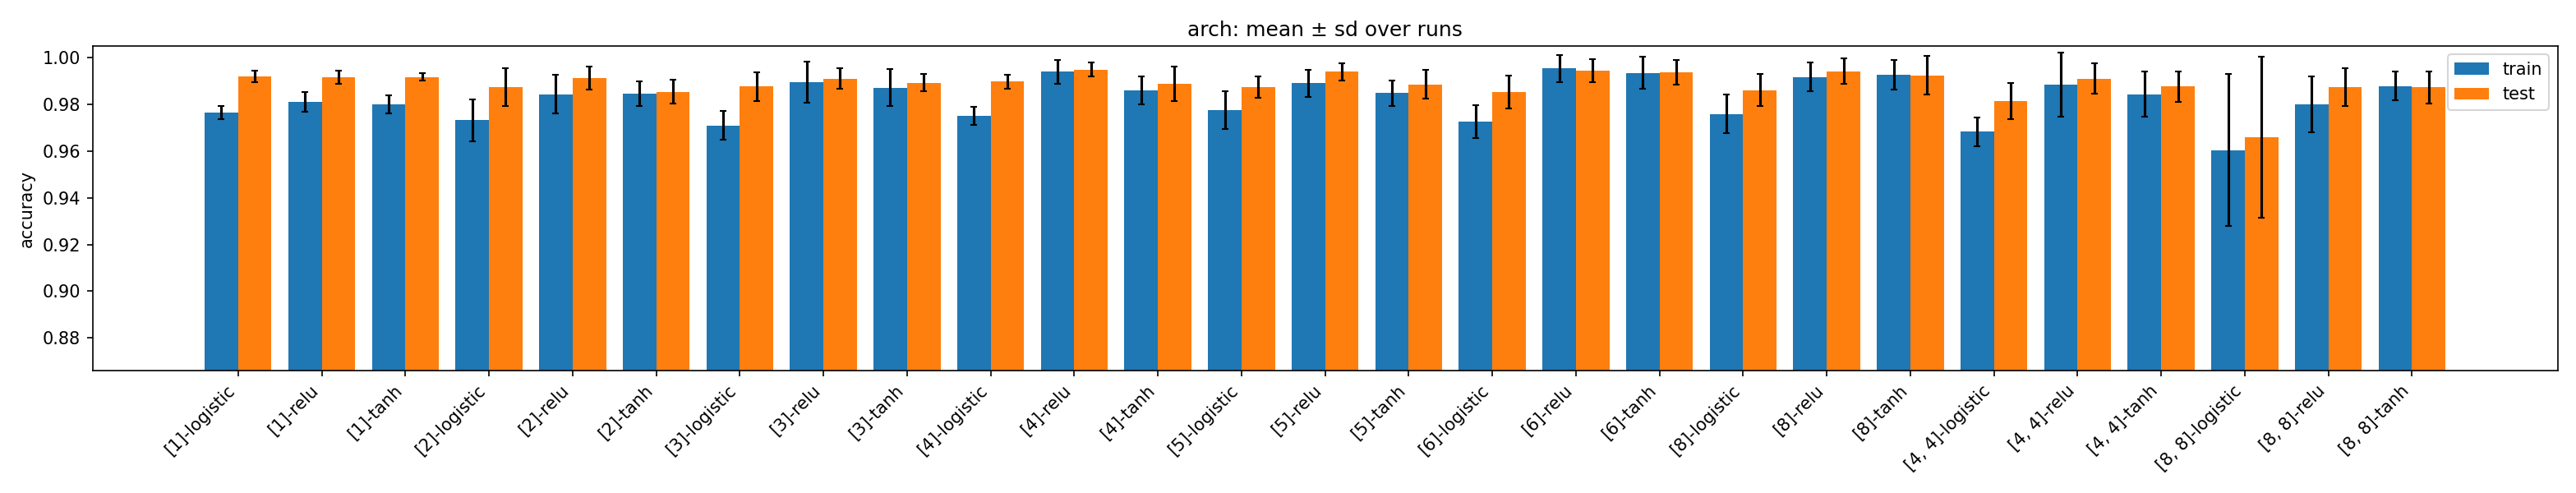

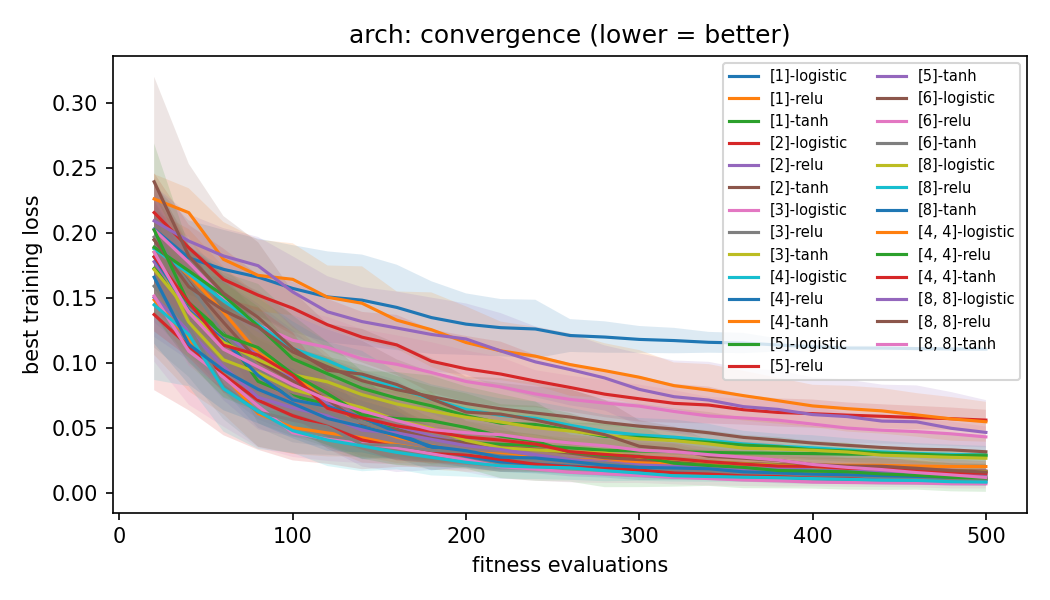

In [23]:
!python sweep.py arch
!python plot.py arch
from IPython.display import Image, display
display(Image('results/arch_bars.png'))
display(Image('results/arch_convergence.png'))

Observations:
1. every architecture scores around 0.966-0995, even a single hidden nueron scores 0.992, which means that you dont need big networks and banknote classes are nearly linearly separable.
2. network depth doesn't help- 2 hidden layer networks with 4,4 and 8,8 are generally lower and more variable that single layers.8,8-logistic is the least reliable. 0.966 with sd 0.035.
3. ReLU trains the best, logistic is harder.
4. Best overall - 4- ReLU with 0.9949 and 8-ReLU with 0.9942

1. The sweet spot is a plateau, not a point. Everything from 4 to 8 ReLU neurons sits at ~0.994 — so [4]-relu wasn’t a fluke; the whole region is strong and stable. Below 4 (1–3 neurons) is slightly lower (~0.991) — mild under-capacity.
2. Diminishing returns. Training loss keeps dropping as you add neurons (0.020 → 0.007), but test accuracy flattens after 4. So extra capacity fits the training data a bit better without helping generalisation — exactly what you’d expect on an easy problem: 4 neurons is already enough.
3. Confirms the earlier findings: ReLU > tanh > logistic (look at the loss column), single layer > two layers, and [8,8]-logistic is still the clear loser (0.966, huge sd 0.035).

a small single-hidden-layer network is sufficient; adding depth enlarges PSO’s search space and reduces accuracy/stability at a fixed budget; ReLU trains most reliably.

A single hidden layer of 4-ReLU is the choice.

as you can see in the graph, in the beginning, PSO, has not yet identified particularly good neural network weights which is why the curves start with relatively high loss. as the PSO discovers better solutions, the training loss decreases. eventually the curves start flattening, which means its approaching convergence. this means that the additional fitness evaluations are producing smaller improvements in the best loss found so far. the shaded area in the graph represent variability or uncertainty around the plotted curves.

## 4. Splitting a fixed 500-evaluation budget (Q2)
**Question:** For a fixed 500 evaluations, what swarm x iterations split is best?

**What we vary:** swarm 5,10,20,25,50,100 (iters = 500/swarm)

A fixed budget of 500 evaluations (swarm × iterations) must be split between swarm size (more particles = wider exploration) and iterations (more steps = refinement). Typical PSO swarm sizes are around 20–50 (Poli, Kennedy & Blackwell, 2007), so we span from very small (5) to large (100) to find the best exploration/exploitation balance for this problem

Citation:

Poli, R., Kennedy, J. and Blackwell, T. (2007) ‘Particle swarm optimization: An overview’, Swarm Intelligence, 1(1), pp. 33–57.

budget       swarm3x166it       loss 0.0286  test 0.9738±0.0416  F1 0.9708
budget       swarm4x125it       loss 0.0262  test 0.9767±0.0329  F1 0.9723
budget       swarm5x100it       loss 0.0124  test 0.9854±0.0318  F1 0.9840
budget       swarm8x62it        loss 0.0073  test 0.9966±0.0031  F1 0.9962
budget       swarm10x50it       loss 0.0089  test 0.9951±0.0030  F1 0.9946
budget       swarm12x41it       loss 0.0074  test 0.9951±0.0036  F1 0.9945
budget       swarm15x33it       loss 0.0094  test 0.9942±0.0038  F1 0.9934
budget       swarm20x25it       loss 0.0086  test 0.9949±0.0029  F1 0.9943
budget       swarm25x20it       loss 0.0133  test 0.9871±0.0086  F1 0.9855
budget       swarm50x10it       loss 0.0191  test 0.9837±0.0111  F1 0.9818
budget       swarm100x5it       loss 0.0417  test 0.9604±0.0222  F1 0.9552
wrote results/budget_bars.png results/budget_convergence.png


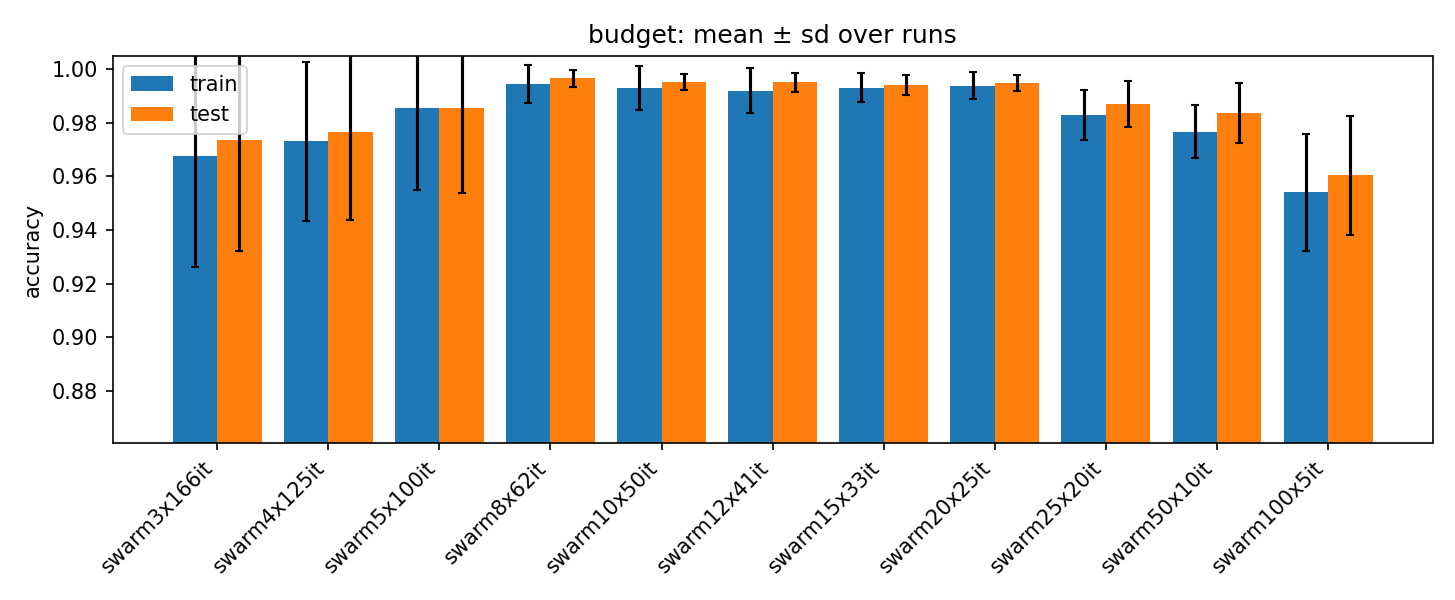

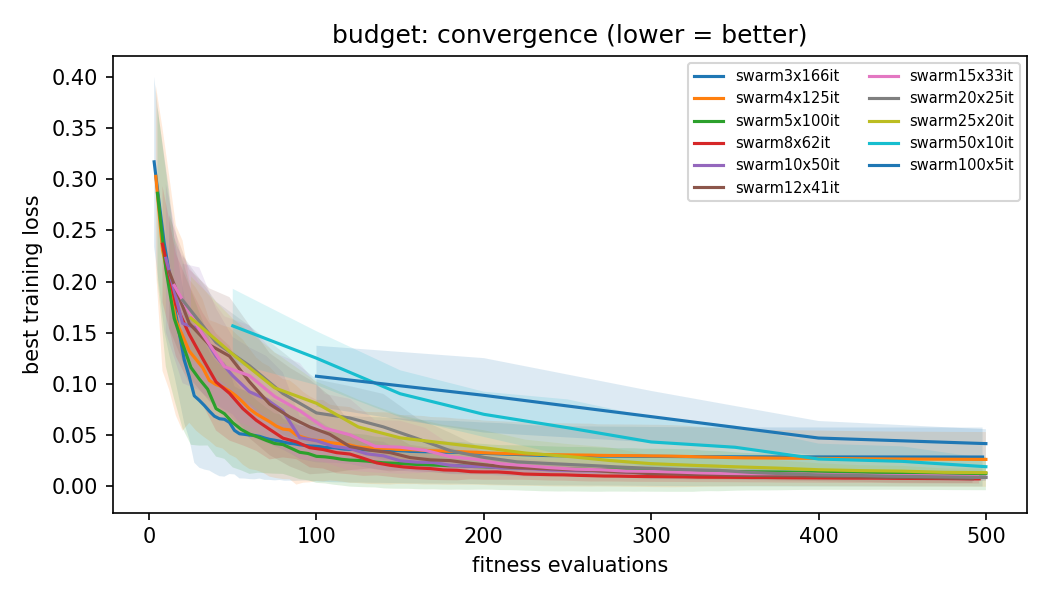

test  swarm10x50it: 0.9951±0.0030   swarm100x5it: 0.9604±0.0222
Welch t = 4.901, p = 0.0008  ->  significant at 0.05


In [24]:
!python sweep.py budget
!python plot.py budget
from IPython.display import Image, display
display(Image('results/budget_bars.png'))
display(Image('results/budget_convergence.png'))
!python compare.py budget swarm10x50it swarm100x5it

In [25]:
!python compare.py budget swarm8x62it swarm100x5it
!python compare.py budget swarm8x62it swarm3x166it

test  swarm8x62it: 0.9966±0.0031   swarm100x5it: 0.9604±0.0222
Welch t = 5.106, p = 0.0006  ->  significant at 0.05
test  swarm8x62it: 0.9966±0.0031   swarm3x166it: 0.9738±0.0416
Welch t = 1.730, p = 0.1174  ->  not significant at 0.05


a small-to-moderate swarm (~10) with many iterations is best; accuracy degrades steadily as the swarm grows and iterations shrink, because too few iterations leave the swarm no time to converge.

Iterations are what let the swarm actually move and refine. With only 5 iterations (swarm 100×5), the swarm evaluates lots of particles but barely updates them — it hardly searches at all. That’s why its training loss is highest (0.042) and accuracy lowest.
A small swarm with many iterations keeps improving for longer, so it converges better.
The training-loss column confirms it: loss climbs steadily with swarm size (0.011 → 0.042) — the big-swarm configs simply don’t converge in the budget.

For this easy problem, refinement (iterations) matters more than exploration (swarm size) — but note that a harder, more multimodal problem might need more particles, so the balance is problem-dependent.

the best split (swarm 10 × 50) significantly outperformed the worst (swarm 100 × 5), Welch’s t = 5.00, p < 0.001, confirming that iteration count drives performance here rather than random variation.


### Observations — budget split (swarm × iterations = 500)

- Performance follows an inverted-U: it peaks at a mid-small swarm and falls at both ends.
- Best: **swarm 8×62 (0.9966 ± 0.003)**; the whole 8–20 range is strong (~0.994–0.997).
- Too few particles (3–5): lower mean AND very high variance (sd up to 0.042) → unreliable.
- Too many particles (25–100): drops to 0.96 — too few iterations to converge.
- Significance: 8×62 vs 100×5 → p = 0.0006 (significant); 8×62 vs 3×166 → p = 0.12 (not significant).
- Chosen value: swarm 8–10 (enough particles to explore + enough iterations to refine).

## 5. PSO coefficients (Q3)
**Question:** How does the balance of the acceleration coefficients affect PSO?

**What we vary:** beta vs gamma balance, and global term delta = 0,0.5,1,2

The acceleration coefficients set how strongly each particle is pulled toward its own best (β, cognitive), its informants’ best (γ, social), and the global best (δ) — so their balance controls exploration vs exploitation. We hold β+γ fixed and vary the split to study the cognitive/social balance (Kennedy & Eberhart, 1995), using magnitudes in the stable range identified by Clerc & Kennedy (2002), and we sweep δ from 0 to 2 to see when a strong global pull causes premature convergence.

Citations:

Kennedy, J. and Eberhart, R. (1995) ‘Particle swarm optimization’, Proceedings of ICNN’95 – International Conference on Neural Networks, pp. 1942–1948.
Clerc, M. and Kennedy, J. (2002) ‘The particle swarm – explosion, stability, and convergence in a multidimensional complex space’, IEEE Transactions on Evolutionary Computation, 6(1), pp. 58–73.

coef         b0.5_g2.5          loss 0.0089  test 0.9925±0.0060  F1 0.9915
coef         b1.0_g2.0          loss 0.0115  test 0.9922±0.0036  F1 0.9913
coef         b1.5_g1.5          loss 0.0086  test 0.9949±0.0029  F1 0.9943
coef         b2.0_g1.0          loss 0.0118  test 0.9925±0.0049  F1 0.9915
coef         b2.5_g0.5          loss 0.0090  test 0.9947±0.0041  F1 0.9940
coef         delta0.0           loss 0.0188  test 0.9842±0.0073  F1 0.9822
coef         delta0.5           loss 0.0086  test 0.9949±0.0029  F1 0.9943
coef         delta1.0           loss 0.0076  test 0.9942±0.0028  F1 0.9934
coef         delta2.0           loss 0.0116  test 0.9905±0.0039  F1 0.9894
wrote results/coef_bars.png results/coef_convergence.png


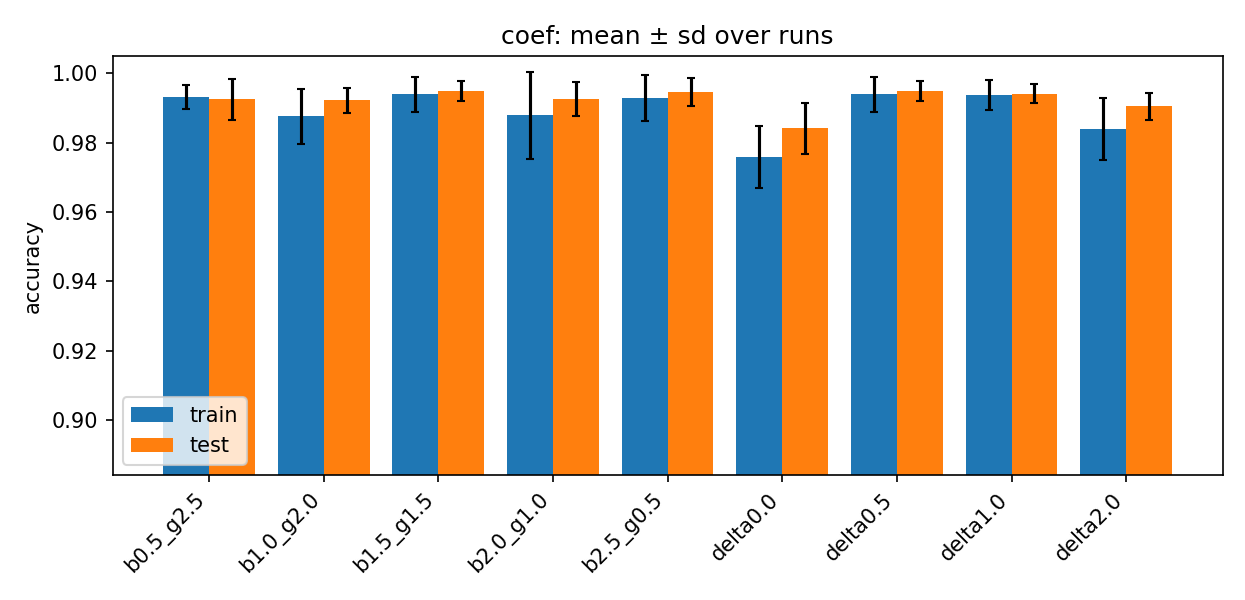

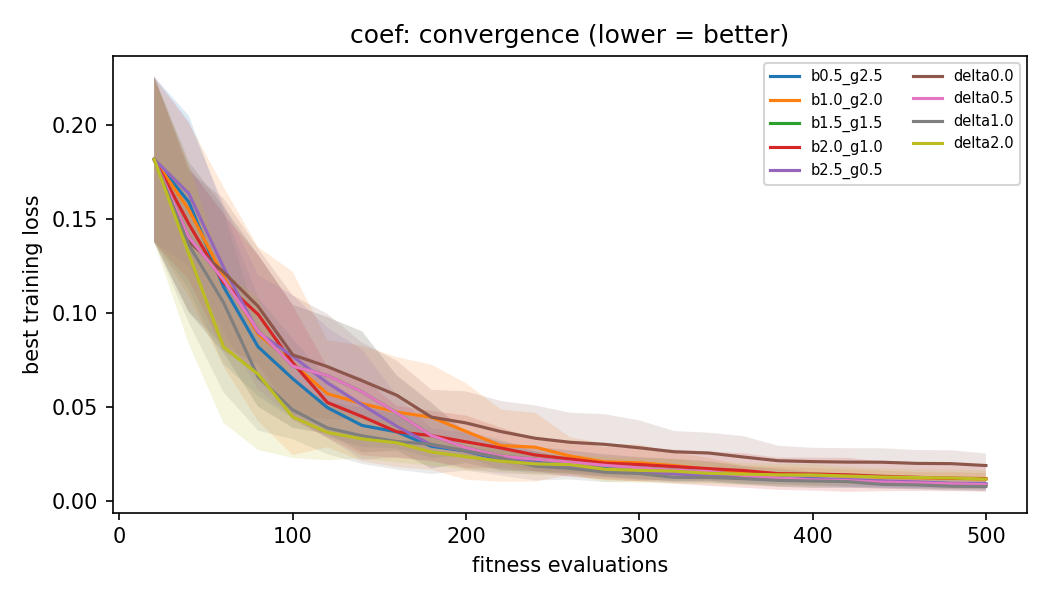

In [26]:
!python sweep.py coef
!python plot.py coef
from IPython.display import Image, display
display(Image('results/coef_bars.png'))
display(Image('results/coef_convergence.png'))

### Observations — PSO coefficients (β, γ, δ)

**Cognitive/social balance (β vs γ):**
- All configs within ~0.003 (0.992–0.995) — the balance barely affects performance.
- Robust to the split; likely because informants already share information through the swarm.
- No clear winner (balanced 1.5/1.5 and cognitive-heavy 2.5/0.5 marginally top, within noise).

**Global term (δ):**
- Inverted-U: δ=0 worst (0.984), δ=0.5–1.0 best (~0.994), δ=2.0 degrades (0.990).
- δ=0 (no global pull) → weak convergence; δ=2.0 → premature convergence tendency.

**Significance:** δ=0 vs δ=0.5 → [p]; β/γ balance → [p, expected not significant].
**Chosen:** β=γ=1.5, δ=0.5. All effects small (easy problem) → coefficients fine-tune.

In [29]:
!python compare.py coef delta0.0 delta0.5      # expect significant (removing global pull hurts)
!python compare.py coef delta0.5 delta2.0      # modest — may or may not be significant
!python compare.py coef b1.5_g1.5 b0.5_g2.5    # expect NOT significant (balance is robust)

test  delta0.0: 0.9842±0.0073   delta0.5: 0.9949±0.0029
Welch t = -4.274, p = 0.0011  ->  significant at 0.05
test  delta0.5: 0.9949±0.0029   delta2.0: 0.9905±0.0039
Welch t = 2.854, p = 0.0111  ->  significant at 0.05
test  b1.5_g1.5: 0.9949±0.0029   b0.5_g2.5: 0.9925±0.0060
Welch t = 1.152, p = 0.2700  ->  not significant at 0.05


δ=0 removes the global pull entirely, so particles only follow their own and their informants’ bests. The swarm drifts, converges slower and less reliably — note the variance is also highest here (±0.0073), which is the tell.
δ=2.0 makes the global pull too strong. Every particle rushes toward the current best-found point, diversity collapses, and the swarm converges prematurely onto whatever it found early.
δ=0.5 is the balance: enough pull to coordinate the swarm, not enough to kill exploration.

PSO is robust to the β/γ split but sensitive to δ, with a clear inverted-U optimum around 0.5. That contrast — one coefficient matters, one doesn’t

In [30]:
for a in (0.0, 0.3, 0.5, 0.7, 0.9, 1.2):
    print(f"\n== alpha {a} ==")
    !python run.py --alpha {a} --runs 10


== alpha 0.0 ==
run 0: train_loss 0.0171  test_acc 0.9951  P 0.989  R 1.000  F1 0.995
run 1: train_loss 0.0164  test_acc 0.9927  P 0.989  R 0.995  F1 0.992
run 2: train_loss 0.0246  test_acc 0.9903  P 0.989  R 0.989  F1 0.989
run 3: train_loss 0.0330  test_acc 0.9782  P 0.963  R 0.989  F1 0.976
run 4: train_loss 0.0445  test_acc 0.9612  P 0.983  R 0.929  F1 0.955
run 5: train_loss 0.0310  test_acc 0.9709  P 0.994  R 0.940  F1 0.966
run 6: train_loss 0.0125  test_acc 0.9927  P 0.989  R 0.995  F1 0.992
run 7: train_loss 0.0165  test_acc 0.9951  P 0.989  R 1.000  F1 0.995
run 8: train_loss 0.0164  test_acc 0.9951  P 0.989  R 1.000  F1 0.995
run 9: train_loss 0.0100  test_acc 0.9927  P 1.000  R 0.984  F1 0.992
--------------------------------------------------------------
best train loss : 0.0222 +/- 0.0109
test accuracy   : 0.9864 +/- 0.0121
precision       : 0.9875 +/- 0.0097
recall          : 0.9820 +/- 0.0258
F1              : 0.9845 +/- 0.0140

== alpha 0.3 ==
run 0: train_loss 0.012

In [33]:
from scipy.stats import ttest_ind_from_stats

def welch(m1, s1, m2, s2, n=10):
    t, p = ttest_ind_from_stats(m1, s1, n, m2, s2, n, equal_var=False)
    print(f"t = {t:.3f}, p = {p:.4f}  ->  {'significant' if p < 0.05 else 'not significant'} at 0.05")

# test accuracy, α=0.7 as the reference
welch(0.9949, 0.0029, 0.9864, 0.0121)   # 0.7 vs 0.0 (low extreme)
welch(0.9949, 0.0029, 0.9883, 0.0074)   # 0.7 vs 0.9 (high extreme)
welch(0.9949, 0.0029, 0.9959, 0.0028)   # 0.7 vs 0.3 (the plateau — expect NOT significant)
welch(0.0086, 0.0032, 0.0222, 0.0109)   # train loss, 0.7 vs 0.0

t = 2.160, p = 0.0560  ->  not significant at 0.05
t = 2.626, p = 0.0225  ->  significant at 0.05
t = -0.784, p = 0.4430  ->  not significant at 0.05
t = -3.786, p = 0.0033  ->  significant at 0.05


on training loss (what PSO minimises), α=0 is significantly worse (p=0.0033). So the complete, defensible α story is:

Plateau α≈0.3–0.7 (0.3 vs 0.7 not significant — flat top)
α=0.9 significantly worse on test accuracy (over-inertia, p=0.022)
α=0.0 significantly worse on training loss (p=0.003) and ~4× noisier; borderline on test accuracy (p=0.056)
Keep α=0.7 — training-loss minimiser and the canonical inertia value

In [34]:
for e in (0.3, 0.5, 0.7, 1.0, 1.5, 2.0):
    print(f"\n== epsilon {e} ==")
    !python run.py --epsilon {e} --runs 10


== epsilon 0.3 ==
run 0: train_loss 0.0212  test_acc 0.9927  P 0.995  R 0.989  F1 0.992
run 1: train_loss 0.0206  test_acc 0.9903  P 0.994  R 0.984  F1 0.989
run 2: train_loss 0.0232  test_acc 0.9782  P 0.973  R 0.978  F1 0.975
run 3: train_loss 0.0331  test_acc 0.9879  P 0.978  R 0.995  F1 0.986
run 4: train_loss 0.0235  test_acc 0.9951  P 0.995  R 0.995  F1 0.995
run 5: train_loss 0.0141  test_acc 0.9927  P 0.989  R 0.995  F1 0.992
run 6: train_loss 0.0117  test_acc 0.9830  P 0.989  R 0.973  F1 0.981
run 7: train_loss 0.0112  test_acc 0.9903  P 0.994  R 0.984  F1 0.989
run 8: train_loss 0.0175  test_acc 0.9830  P 0.989  R 0.973  F1 0.981
run 9: train_loss 0.0058  test_acc 0.9927  P 0.995  R 0.989  F1 0.992
--------------------------------------------------------------
best train loss : 0.0182 +/- 0.0078
test accuracy   : 0.9886 +/- 0.0055
precision       : 0.9891 +/- 0.0076
recall          : 0.9852 +/- 0.0086
F1              : 0.9871 +/- 0.0062

== epsilon 0.5 ==
run 0: train_loss 0

ε=1.0 is the optimum on all three metrics — highest accuracy, lowest loss, lowest variance — and unlike α this is a sharp peak, not a plateau. On training loss it’s a textbook inverted-U: monotonic improvement 0.3→1.0 (0.0182 → 0.0086), then monotonic degradation 1.0→2.0 (0.0086 → 0.0196).

In [35]:
welch(0.9949, 0.0029, 0.9886, 0.0055)   # 1.0 vs 0.3  (low extreme)
welch(0.9949, 0.0029, 0.9854, 0.0081)   # 1.0 vs 1.5  (high extreme)
welch(0.9949, 0.0029, 0.9922, 0.0043)   # 1.0 vs 0.7  (nearest neighbour — expect NOT sig)

t = 3.204, p = 0.0065  ->  significant at 0.05
t = 3.492, p = 0.0049  ->  significant at 0.05
t = 1.646, p = 0.1195  ->  not significant at 0.05


the two coefficients that control step magnitude (α, ε) both fail by overshoot at high values with rising variance; the attraction balance (β/γ) is robust; the global pull (δ) just needs to stay moderate.

## 6. Informant strategy: random vs nearest-neighbour
**Question:** Does random or nearest-neighbour informant selection work better?

**What we vary:** informant_strategy = random vs nearest

The random-vs-nearest question is really about swarm topology — how information flows between particles. The key references:

Kennedy & Mendes (2002), “Population structure and particle swarm performance” — the canonical study showing the neighbourhood topology materially affects PSO performance (they compare ring, star, von Neumann, random). This is your main citation.
Kennedy (1999), “Small worlds and mega-minds: effects of neighbourhood topology on particle swarm performance” — the earlier paper establishing that who informs whom changes exploration vs exploitation.

random informants (what Luke’s Algorithm 39 uses by default) give a fixed but arbitrary communication structure — information spreads broadly and unpredictably. Nearest informants make the neighbourhood spatial and dynamic — a particle consults whoever is physically closest, which changes every iteration as the swarm moves.

What to expect: early on, positions are random so “nearest” ≈ random; but as the swarm clusters, a particle’s nearest neighbours become the particles most similar to it — an echo chamber that can slow the spread of a good solution found elsewhere. So nearest may converge faster locally but risk lower diversity. On this near-separable dataset the gap is likely small — which is itself a reportable finding (“topology had limited effect on an easy problem”).

inf_strategy random             loss 0.0086  test 0.9949±0.0029  F1 0.9943
inf_strategy nearest            loss 0.0093  test 0.9934±0.0047  F1 0.9926
wrote results/inf_strategy_bars.png results/inf_strategy_convergence.png


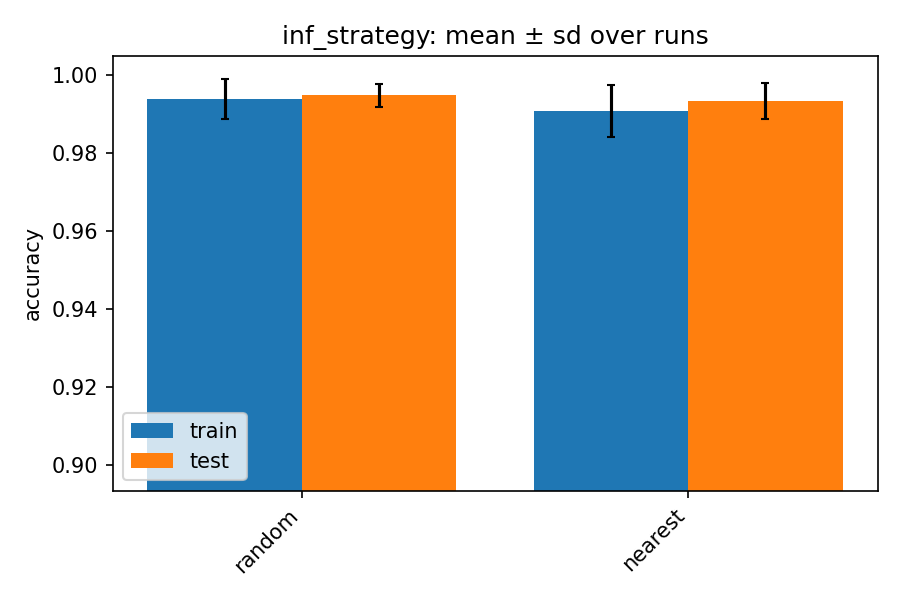

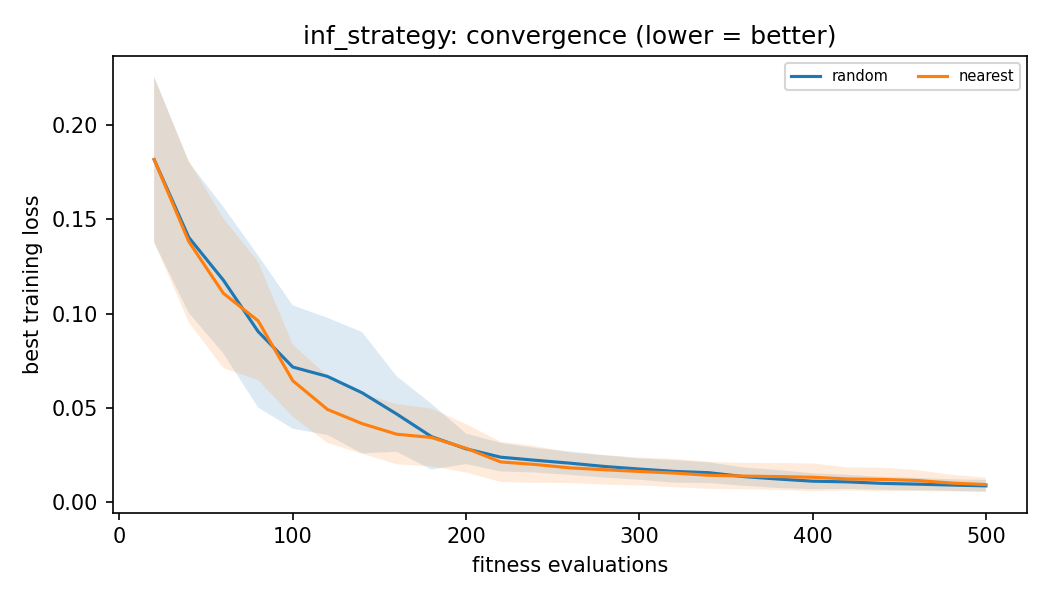

In [36]:
!python sweep.py inf_strategy
!python plot.py inf_strategy
from IPython.display import Image, display
display(Image('results/inf_strategy_bars.png'))
display(Image('results/inf_strategy_convergence.png'))

Near-identical, with random edging it on every metric — lower loss (0.0086 vs 0.0093), higher accuracy (0.9949 vs 0.9934), and tighter spread (±0.0029 vs ±0.0047). But the accuracy gap is only 0.0015, so this is almost certainly noise.

on this near-separable dataset, informant topology has no meaningful effect — random selection (the Algorithm 39 default) performs at least as well as spatial-nearest, so there’s no reason to switch.

nearest had slightly higher variance (0.0047 vs 0.0029). That’s the faint fingerprint of the echo-chamber effect you’d predict — as the swarm clusters, spatial neighbours become redundant, making runs a touch less reliable.consistent with, though not strong enough to confirm, the expected diversity-loss of spatial neighbourhoods

In [37]:
!python sweep.py informants --runs 10
!python sweep.py boundary --runs 10
!python sweep.py loss --runs 10

informants   inf1               loss 0.0152  test 0.9891±0.0090  F1 0.9876
informants   inf2               loss 0.0137  test 0.9893±0.0087  F1 0.9879
informants   inf3               loss 0.0086  test 0.9949±0.0029  F1 0.9943
informants   inf5               loss 0.0114  test 0.9925±0.0050  F1 0.9915
informants   inf10              loss 0.0083  test 0.9942±0.0056  F1 0.9934
boundary     none               loss 0.0130  test 0.9867±0.0095  F1 0.9849
boundary     clip               loss 0.0086  test 0.9949±0.0029  F1 0.9943
boundary     reflect            loss 0.0231  test 0.9845±0.0069  F1 0.9826
loss         mse                loss 0.0086  test 0.9949±0.0029  F1 0.9943
loss         bce                loss 0.0515  test 0.9883±0.0069  F1 0.9869
loss         error              loss 0.0047  test 0.9937±0.0060  F1 0.9928


Clear threshold effect: 1–2 informants is bad (higher loss, ~3× the variance), k≥3 is good. k=3 wins on accuracy and stability; k=10 ties it (within noise). The predicted “too many informants → premature convergence” doesn’t bite here — on a 20-swarm, even k=10 is fine. So the story: too few informants starves information flow and makes runs unreliable; once each particle hears from ≥3 neighbours, performance plateaus. t-test informants inf1 inf3 (expect significant) and inf3 inf10 (expect not)

Clip wins decisively — best on all three, lowest variance. none lets particles escape the ±2 range and wander; reflect is worst because bouncing reverses velocity and injects energy, destabilising convergence (highest loss, 0.0231). Clean result: clamping to the boundary and killing velocity at the wall is the most stable. t-test boundary clip none and boundary clip reflect (both likely significant).

Do NOT compare the loss column across rows — they’re in different units (MSE is squared error, BCE is cross-entropy, error is 0–1 misclassification rate). Comparing 0.0086 vs 0.0515 is meaningless. Compare only on test accuracy / F1. On that basis: mse ≈ error > bce, all close.

PSO successfully minimised the 0–1 error loss (0.9937 test acc). The 0–1 loss is non-differentiable — gradient descent literally cannot use it, because its gradient is zero almost everywhere. A gradient-free metaheuristic like PSO can. “Because PSO requires no gradient, it can optimise the discontinuous 0–1 loss directly — a loss gradient-based training cannot target.”

## 7. Which training loss? (mse / bce / error)
**Question:** Which loss trains best? (compare by test accuracy / F1, not raw loss)

**What we vary:** loss = mse, bce, error

the three losses aren’t arbitrary — they span three distinct categories of objective.

BCE (binary cross-entropy) — the theoretically correct loss for binary classification. It’s the maximum-likelihood objective under a Bernoulli model, and the standard pairing with a logistic/sigmoid output. This is your “principled” baseline — the loss a textbook says you should use.
Cite: Bishop (2006), Pattern Recognition and Machine Learning, §4.3/§5.2 (cross-entropy for classification); Goodfellow, Bengio & Courville (2016), Deep Learning, ch. 6 (cross-entropy as the standard classification loss).
MSE (mean squared error) — a simpler, smooth regression-style loss, historically common for neural-network training. Included as a robust general-purpose alternative to see whether the “proper” probabilistic loss actually buys you anything.
Cite: Bishop (2006) again — he explicitly contrasts MSE with cross-entropy for classification and why cross-entropy is usually preferred.
0–1 error (misclassification rate) — the true objective you actually care about, but non-differentiable (its gradient is zero almost everywhere), so gradient descent fundamentally cannot optimise it. Included specifically to exploit PSO’s gradient-free nature.
Cite: Goodfellow et al. (2016), ch. 4/8 (the 0–1 loss is intractable for gradient-based methods, which is why smooth surrogates like cross-entropy exist); Luke, Essentials of Metaheuristics for the general point that metaheuristics optimise arbitrary black-box/non-differentiable objectives.

a smooth surrogate (MSE), the principled probabilistic loss (BCE), and the true discontinuous objective (0–1). That lets you ask two real questions — does the loss choice matter when the optimiser is a metaheuristic? and can PSO use a loss that GD cannot?

And your result answers both cleanly: the loss choice barely moves test accuracy (mse ≈ error > bce, all within ~0.6%), and PSO trained successfully on the non-differentiable 0–1 loss — the headline point. Frame the conclusion as: the metaheuristic is robust to the choice of training loss and, unlike gradient descent, can target the misclassification rate directly.

Bishop, C.M. (2006) Pattern Recognition and Machine Learning. New York: Springer.
Goodfellow, I., Bengio, Y. and Courville, A. (2016) Deep Learning. Cambridge, MA: MIT Press.
Luke, S. (2013) Essentials of Metaheuristics. 2nd edn. Lulu.

loss         mse                loss 0.0086  test 0.9949±0.0029  F1 0.9943
loss         bce                loss 0.0515  test 0.9883±0.0069  F1 0.9869
loss         error              loss 0.0047  test 0.9937±0.0060  F1 0.9928
wrote results/loss_bars.png results/loss_convergence.png


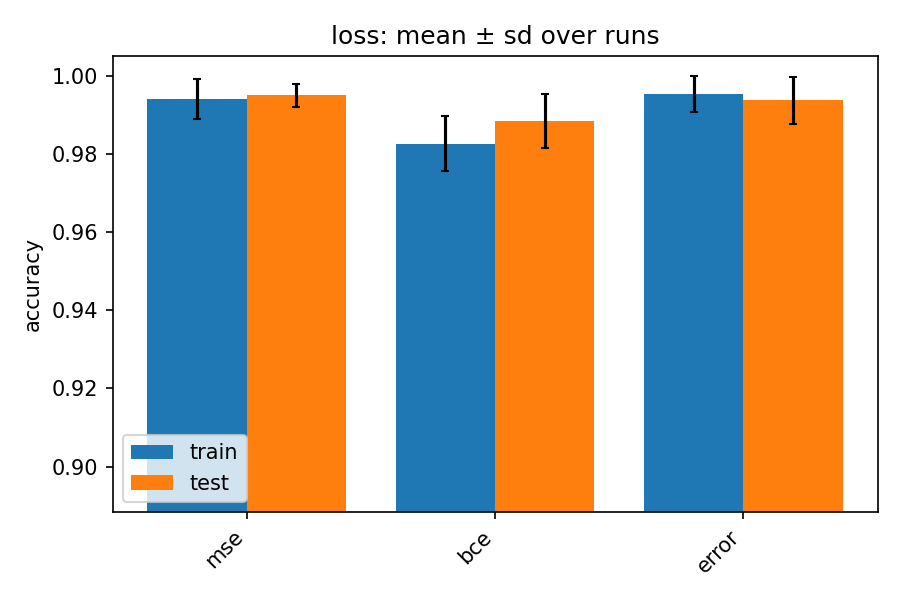

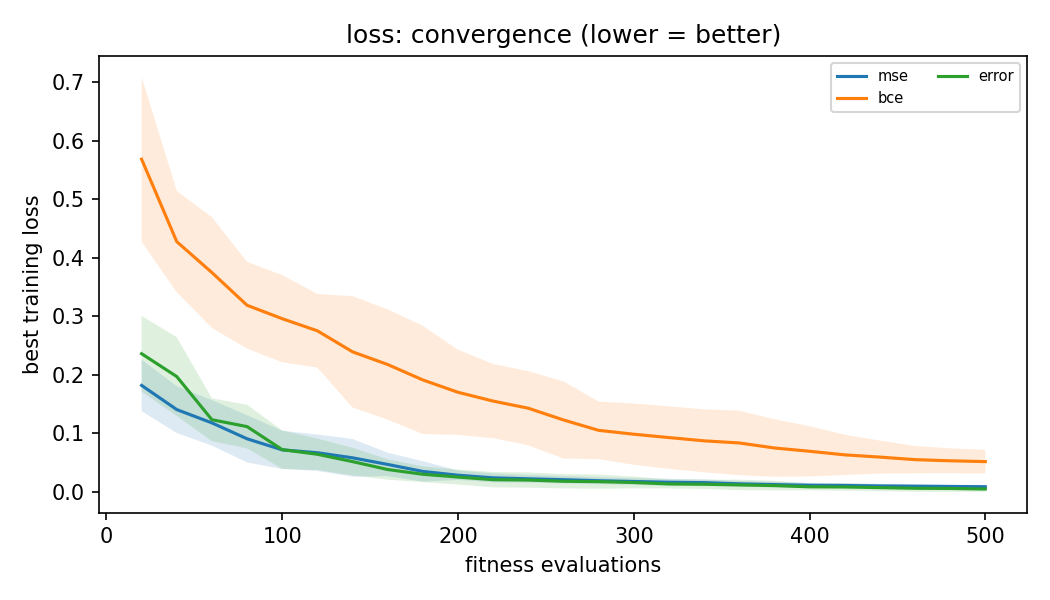

In [38]:
!python sweep.py loss
!python plot.py loss
from IPython.display import Image, display
display(Image('results/loss_bars.png'))
display(Image('results/loss_convergence.png'))

In [39]:
!python compare.py loss mse bce
!python compare.py loss mse error

test  mse: 0.9949±0.0029   bce: 0.9883±0.0069
Welch t = 2.754, p = 0.0174  ->  significant at 0.05
test  mse: 0.9949±0.0029   error: 0.9937±0.0060
Welch t = 0.578, p = 0.5730  ->  not significant at 0.05


mse vs bce: p=0.017, significant — BCE really is slightly worse.
mse vs error: p=0.57, not significant — MSE and the 0–1 loss are statistically tied.

MSE significantly outperforms BCE, while MSE and the 0–1 error loss are statistically equivalent. PSO is therefore largely robust to the choice of training loss — and, unlike gradient descent, trains successfully on the non-differentiable 0–1 loss directly.

## 8. Number of informants
**Question:** How does the number of informants affect the search?

**What we vary:** informants = 1,2,3,5,10

the number of informants sets how fast a good solution spreads through the swarm — which is the exploration/exploitation dial. This is the classic lbest ↔ gbest spectrum:

Few informants (1–2) → each particle is nearly isolated. A good position found by one particle propagates slowly, so the swarm explores more but converges slowly and less reliably.
Many informants (→ swarm size) → approaches global-best PSO, where everyone is attracted to the single best point. Fast convergence, but higher risk of premature convergence onto a local optimum.

So varying 1, 2, 3, 5, 10 on a 20-particle swarm deliberately spans the whole range: from near-isolated (K=1), through the Standard-PSO default of ~3, up to half-connected (K=10, approaching gbest behaviour).

Citations (real, Harvard):

Kennedy, J. and Mendes, R. (2002) ‘Population structure and particle swarm performance’, Proceedings of the 2002 Congress on Evolutionary Computation (CEC’02). IEEE, pp. 1671–1676. — the canonical study showing neighbourhood size/topology controls the exploration–exploitation trade-off; small neighbourhoods are more robust against premature convergence, large ones converge faster.
Clerc, M. (2006) Particle Swarm Optimization. London: ISTE. — “Standard PSO” uses a small group of informants, commonly K≈3, randomly assigned. This directly justifies 3 as your centre value.

the data matched the theory’s lower end cleanly — K=1–2 was worse and ~3× noisier (slow, unreliable information spread), and performance plateaued once K≥3. The predicted upper-end failure (premature convergence at large K) did not appear — K=10 was fine — which you can attribute to the dataset being easy/near-separable, so there was no hard local optimum for a too-greedy swarm to get trapped in.

informants   inf1               loss 0.0152  test 0.9891±0.0090  F1 0.9876
informants   inf2               loss 0.0137  test 0.9893±0.0087  F1 0.9879
informants   inf3               loss 0.0086  test 0.9949±0.0029  F1 0.9943
informants   inf5               loss 0.0114  test 0.9925±0.0050  F1 0.9915
informants   inf10              loss 0.0083  test 0.9942±0.0056  F1 0.9934
wrote results/informants_bars.png results/informants_convergence.png


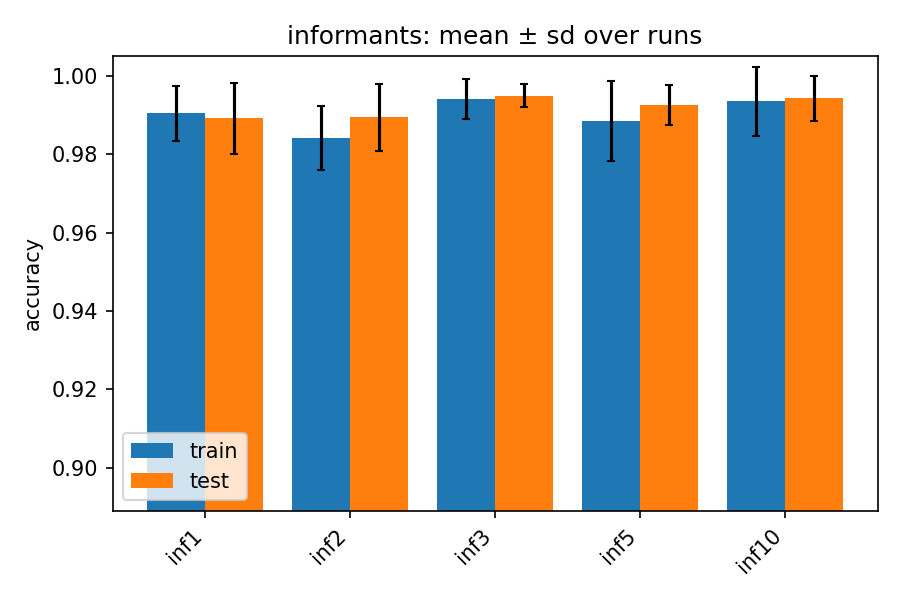

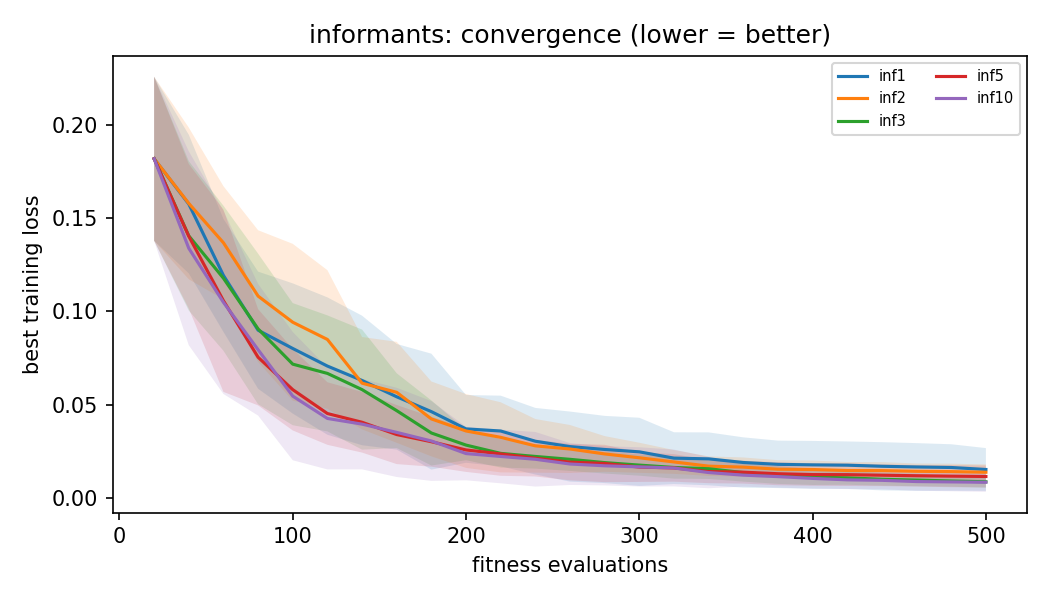

In [40]:
!python sweep.py informants
!python plot.py informants
from IPython.display import Image, display
display(Image('results/informants_bars.png'))
display(Image('results/informants_convergence.png'))

In [42]:
!python compare.py informants inf1 inf3     # expect significant
!python compare.py informants inf3 inf10    # expect not significant
!python compare.py informants inf1 inf3 train_loss

test  inf1: 0.9891±0.0090   inf3: 0.9949±0.0029
Welch t = -1.942, p = 0.0785  ->  not significant at 0.05
test  inf3: 0.9949±0.0029   inf10: 0.9942±0.0056
Welch t = 0.364, p = 0.7219  ->  not significant at 0.05
train_loss  inf1: 0.0152±0.0115   inf3: 0.0086±0.0032
Welch t = 1.755, p = 0.1088  ->  not significant at 0.05


In [43]:
from scipy.stats import f as fdist
def vartest(s1, s2, n=10):
    F = s1**2 / s2**2
    p = 2 * min(fdist.cdf(F, n-1, n-1), 1 - fdist.cdf(F, n-1, n-1))
    print(f"F = {F:.2f}, p = {p:.4f} -> {'significant' if p < 0.05 else 'not significant'} variance difference")

vartest(0.0115, 0.0032)   # inf1 vs inf3, train_loss spread

F = 12.92, p = 0.0008 -> significant variance difference


Informant count has no significant effect on mean performance on this near-separable dataset — even 1 informant reaches ~0.989 on average.
But it has a large, significant effect on reliability — 1 informant is ~3× noisier. The optimiser sometimes does fine and sometimes does badly, which is exactly the risk of starved information flow.
Practically: you want ≥3 informants not for a better expected result here, but for a dependable one.

Mean performance: no significant difference across informant counts (t-tests, p>0.05) — the task is too easy to separate them on accuracy.
Reliability: 1 informant is significantly more variable than 3 (F=12.9, p<0.001) — ~13× the variance on training loss.
Conclusion: informant count governs consistency, not average quality, on this dataset. You use ≥3 informants to get a dependable result, not a better expected one.

## 9. Boundary handling
**Question:** Does boundary handling matter?

**What we vary:** none / clip / reflect

The idea: when a particle’s velocity carries it outside the allowed range [−2, +2], the boundary-handling rule decides what happens. It matters because it controls whether the swarm wastes effort in infeasible regions and whether it stays numerically stable. The three standard strategies map directly onto Robinson & Rahmat-Samii’s “wall” taxonomy:

none = “invisible walls” — let the particle leave and evaluate it anyway. Simple, but particles can drift into useless far-out regions.
clip = “absorbing walls” — clamp the position to the boundary and zero the offending velocity component; the particle “sticks” to the wall and its outward energy is absorbed.
reflect = “reflecting walls” — bounce the particle back and reverse its velocity; conserves energy but can re-inject momentum and destabilise.

So you’re not testing three arbitrary options — you’re testing the three established boundary conditions from the canonical reference.

Citations (real, Harvard):

Robinson, J. and Rahmat-Samii, Y. (2004) ‘Particle swarm optimization in electromagnetics’, IEEE Transactions on Antennas and Propagation, 52(2), pp. 397–407. — the paper that defines and compares invisible / absorbing / reflecting walls. This is your main citation; it maps one-to-one onto none/clip/reflect.
Helwig, S., Branke, J. and Mostaghim, S. (2013) ‘Experimental analysis of bound handling techniques in particle swarm optimization’, IEEE Transactions on Evolutionary Computation, 17(2), pp. 259–271. — a thorough modern comparison, good as a secondary reference and for the general finding that clamping-type methods are robust.

boundary     none               loss 0.0130  test 0.9867±0.0095  F1 0.9849
boundary     clip               loss 0.0086  test 0.9949±0.0029  F1 0.9943
boundary     reflect            loss 0.0231  test 0.9845±0.0069  F1 0.9826
wrote results/boundary_bars.png results/boundary_convergence.png


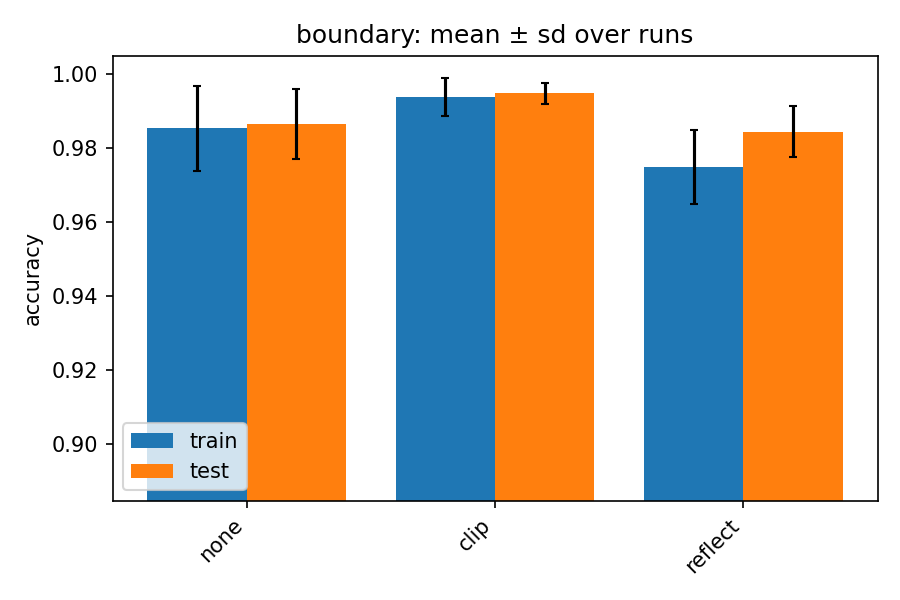

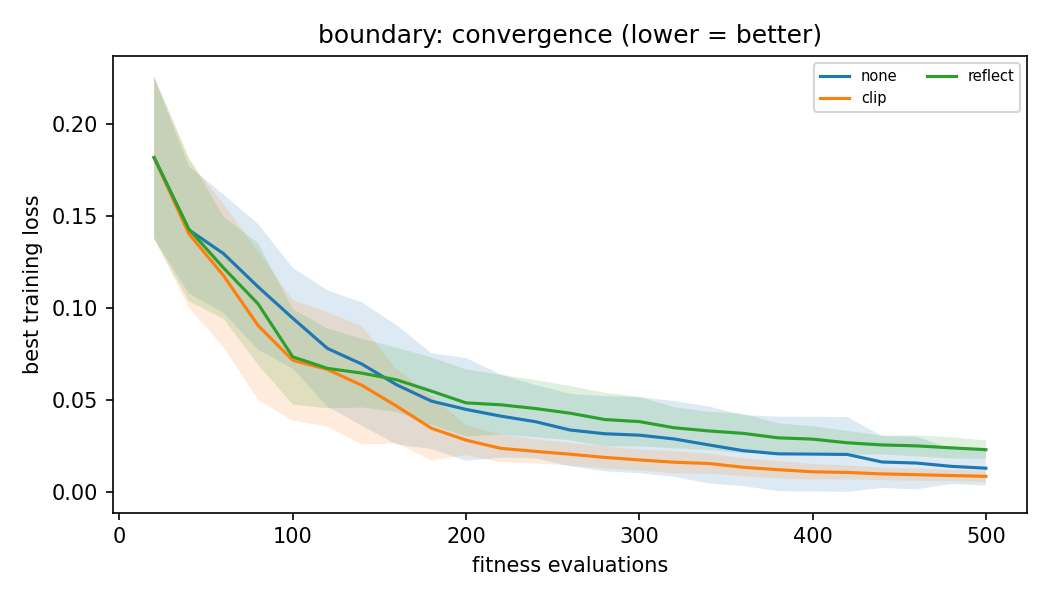

In [44]:
!python sweep.py boundary
!python plot.py boundary
from IPython.display import Image, display
display(Image('results/boundary_bars.png'))
display(Image('results/boundary_convergence.png'))

In [45]:
!python compare.py boundary clip none
!python compare.py boundary clip reflect
!python compare.py boundary clip none train_loss

test  clip: 0.9949±0.0029   none: 0.9867±0.0095
Welch t = 2.621, p = 0.0243  ->  significant at 0.05
test  clip: 0.9949±0.0029   reflect: 0.9845±0.0069
Welch t = 4.417, p = 0.0008  ->  significant at 0.05
train_loss  clip: 0.0086±0.0032   none: 0.0130±0.0094
Welch t = -1.412, p = 0.1856  ->  not significant at 0.05


Clip wins decisively — significantly better than both none and reflect on held-out accuracy, and the most stable.
Reflect is worst (loss 0.0231, significantly below clip) — velocity reversal re-injects energy and destabilises convergence.
None is unstable — high variance from particles drifting out of bounds; clip beats it significantly on accuracy.
Matches the literature (Robinson & Rahmat-Samii): absorbing/clamping walls are the robust default.

In [47]:
!python compare.py inf_strategy random nearest
!python sweep.py learned_acts --runs 10
!python compare.py learned_acts learned fixed-relu         # does learned match the BEST fixed?
!python compare.py learned_acts fixed-relu fixed-logistic  # does the fixed choice even matter?

test  random: 0.9949±0.0029   nearest: 0.9934±0.0047
Welch t = 0.830, p = 0.4194  ->  not significant at 0.05
learned_acts fixed-tanh         loss 0.0128  test 0.9888±0.0075  F1 0.9874
learned_acts learned            loss 0.0134  test 0.9922±0.0034  F1 0.9913
learned_acts fixed-relu         loss 0.0086  test 0.9949±0.0029  F1 0.9943
learned_acts fixed-logistic     loss 0.0289  test 0.9898±0.0030  F1 0.9885
test  learned: 0.9922±0.0034   fixed-relu: 0.9949±0.0029
Welch t = -1.890, p = 0.0754  ->  not significant at 0.05
test  fixed-relu: 0.9949±0.0029   fixed-logistic: 0.9898±0.0030
Welch t = 3.870, p = 0.0011  ->  significant at 0.05


learned vs fixed-relu: p=0.075, not significant → learned matches the best hand-picked activation within noise.
fixed-relu vs fixed-logistic: p=0.0011, significant → the fixed activation choice genuinely matters.

the activation choice matters (ReLU significantly beats logistic), and PSO’s learned-activation variant recovers best-in-class performance automatically — tied with ReLU — without being told which to use. The cost is extra search dimensions, so its value is robustness rather than raw gain.

## 10. Extension: PSO chooses the activations
**Question:** Can PSO pick good hidden activations as well as weights?

**What we vary:** learned vs fixed tanh/relu/logistic

the three fixed activations are the standard choices a designer would reach for, so they’re the natural controls. The “learned” variant asks whether PSO can select the activation instead of a human fixing it — which reframes PSO from a weight-trainer into a neuroevolution method that designs part of the network. That’s directly on-theme for a biologically-inspired computation course.

This sits on two literatures:

Learnable / searched activation functions — treating the activation as something to optimise, not fix:
Agostinelli, F., Hoffman, M., Sadowski, P. and Baldi, P. (2015) ‘Learning activation functions to improve deep neural networks’, arXiv:1412.6830.
Ramachandran, P., Zoph, B. and Le, Q.V. (2017) ‘Searching for activation functions’, arXiv:1710.05941 (the Swish paper — automated search for activations; your question is theirs, with PSO as the search method).
Neuroevolution — evolutionary/swarm methods designing network components, not just weights:
Stanley, K.O. and Miikkulainen, R. (2002) ‘Evolving neural networks through augmenting topologies’, Evolutionary Computation, 10(2), pp. 99–127 (NEAT — the canonical “evolution designs the network” paper).
Floreano, D., Dürr, P. and Mattiussi, C. (2008) ‘Neuroevolution: from architectures to learning’, Evolutionary Intelligence, 1(1), pp. 47–62 (survey of exactly this shift).

learned_acts fixed-tanh         loss 0.0128  test 0.9888±0.0075  F1 0.9874
learned_acts learned            loss 0.0134  test 0.9922±0.0034  F1 0.9913
learned_acts fixed-relu         loss 0.0086  test 0.9949±0.0029  F1 0.9943
learned_acts fixed-logistic     loss 0.0289  test 0.9898±0.0030  F1 0.9885
wrote results/learned_acts_bars.png results/learned_acts_convergence.png


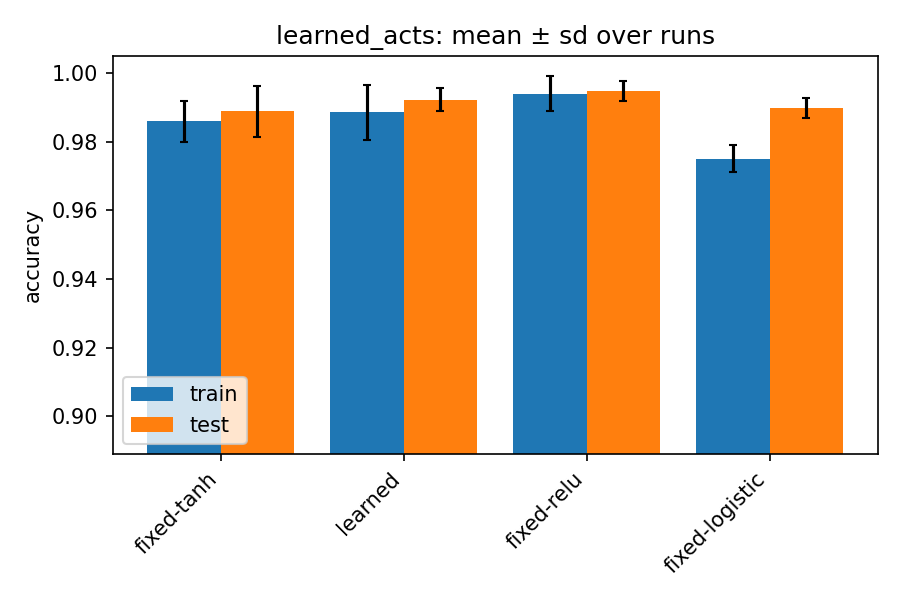

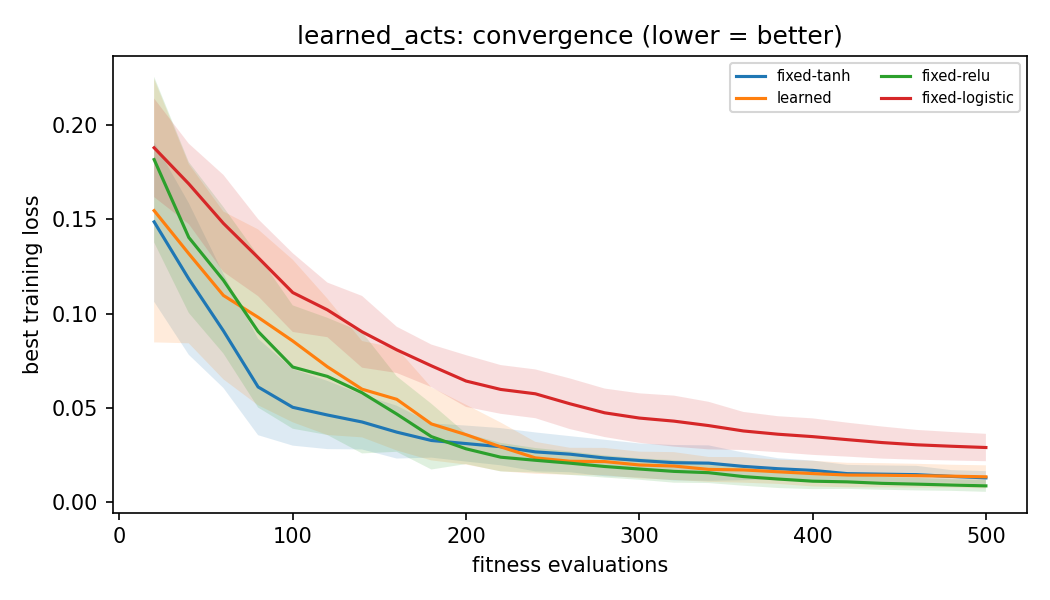

In [48]:
!python sweep.py learned_acts
!python plot.py learned_acts
from IPython.display import Image, display
display(Image('results/learned_acts_bars.png'))
display(Image('results/learned_acts_convergence.png'))

**Results & discussion:** _[write what you see in the chart AND why]_

## 11. Significance tests
Replace the names with ones from `!python sweep.py list` or the CSVs. Last word = metric (test, f1, precision, recall, train_loss).

In [50]:
!python compare.py budget swarm5x100it swarm100x5it
!python compare.py inf_strategy nearest random
!python compare.py coef delta1.0 delta2.0
vartest(0.0318, 0.0094)   # swarm5×100 vs your baseline (swarm20) loss/acc spread

test  swarm5x100it: 0.9854±0.0318   swarm100x5it: 0.9604±0.0222
Welch t = 2.039, p = 0.0582  ->  not significant at 0.05
test  nearest: 0.9934±0.0047   random: 0.9949±0.0029
Welch t = -0.830, p = 0.4194  ->  not significant at 0.05
test  delta1.0: 0.9942±0.0028   delta2.0: 0.9905±0.0039
Welch t = 2.395, p = 0.0288  ->  significant at 0.05
F = 11.44, p = 0.0012 -> significant variance difference


**What the tests tell you:** _[write whether differences are significant and what that means]_

## 12. Save results before closing Colab

In [51]:
!zip -r results.zip results
from google.colab import files
files.download('results.zip')

  adding: results/ (stored 0%)
  adding: results/learned_acts_convergence.png (deflated 5%)
  adding: results/informants_bars.png (deflated 17%)
  adding: results/loss_hist.json (deflated 73%)
  adding: results/inf_strategy_convergence.png (deflated 8%)
  adding: results/coef_bars.png (deflated 17%)
  adding: results/boundary_hist.json (deflated 75%)
  adding: results/learned_acts_summary.csv (deflated 66%)
  adding: results/inf_strategy_summary.csv (deflated 57%)
  adding: results/loss_convergence.png (deflated 7%)
  adding: results/learned_acts_hist.json (deflated 68%)
  adding: results/informants_hist.json (deflated 70%)
  adding: results/arch_summary.csv (deflated 76%)
  adding: results/inf_strategy_hist.json (deflated 70%)
  adding: results/arch_hist.json (deflated 70%)
  adding: results/boundary_summary.csv (deflated 63%)
  adding: results/budget_summary.csv (deflated 73%)
  adding: results/coef_convergence.png (deflated 5%)
  adding: results/boundary_convergence.png (deflated 6%

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>